In [1]:
pip install torch torchvision transformers pillow faiss-cpu pandas numpx y matplotlib tqdm

ERROR: Could not find a version that satisfies the requirement numpx (from versions: none)
ERROR: No matching distribution found for numpx
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
DATA_DIR = "/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits"

print(os.listdir(DATA_DIR))

['labels', 'val.txt', 'test.txt', 'categories.csv', 'labels.cache', 'images', 'disjoint', 'nondisjoint', 'train.txt', 'polyvore.yaml', 'polyvore_outfit_titles.json', 'polyvore_item_metadata.json']


In [3]:
import pandas as pd
categories = pd.read_csv('/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/categories.csv')

In [4]:
categories.head()

,category_id,sub_category,main_category
0,3,dress,all-body
1,4,dress,all-body
2,5,dress,all-body
3,6,gown,all-body
4,7,skirt,bottoms


In [5]:
categories.shape

(194, 3)

In [6]:
categories.columns

Index(['category_id', 'sub_category', 'main_category'], dtype='object')

In [7]:
categories.isnull().sum()

category_id      0
sub_category     0
main_category    5
dtype: int64

In [8]:
categories[categories["main_category"].isnull()]

,category_id,sub_category,main_category
96,245,lingerie top,NaN
97,246,lingerie bottom,NaN
98,247,lingerie top,NaN
133,283,male boxers,NaN
135,285,male sports shirt/track suit,NaN


In [9]:
categories["main_category"].value_counts(dropna=False)

main_category
tops            35
shoes           32
bottoms         31
accessories     22
bags            18
outerwear       13
all-body        11
jewellery        9
hats             6
NaN              5
jewellery        4
accessories      4
scarves          2
sunglasses       2
Name: count, dtype: int64

In [10]:
categories["category_id"].duplicated().sum()

np.int64(36)

In [11]:
duplicates = categories[
    categories["category_id"].duplicated(keep=False)
]

duplicates.sort_values("category_id")

,category_id,sub_category,main_category
8,11,sweater,tops
9,11,sleeveless top,tops
10,11,shirt,tops
11,11,top,tops
13,17,blouse,tops
...,...,...,...
114,261,booties,shoes
161,318,purse,bags
162,318,handbag,bags
189,4495,sweathirt,tops


In [12]:
categories["category_id"].value_counts()[
    categories["category_id"].value_counts() > 1
]

category_id
55      5
17      4
11      4
37      3
25      3
41      3
24      2
19      2
36      2
28      2
46      2
51      2
43      2
21      2
4495    2
318     2
261     2
259     2
106     2
64      2
65      2
104     2
62      2
49      2
61      2
57      2
Name: count, dtype: int64

In [13]:
duplicates.sort_values("category_id")

,category_id,sub_category,main_category
8,11,sweater,tops
9,11,sleeveless top,tops
10,11,shirt,tops
11,11,top,tops
13,17,blouse,tops
...,...,...,...
114,261,booties,shoes
161,318,purse,bags
162,318,handbag,bags
189,4495,sweathirt,tops


In [14]:
categories["main_category"].value_counts(dropna=False)

main_category
tops            35
shoes           32
bottoms         31
accessories     22
bags            18
outerwear       13
all-body        11
jewellery        9
hats             6
NaN              5
jewellery        4
accessories      4
scarves          2
sunglasses       2
Name: count, dtype: int64

### Categories Dataset Inspection

The categories file contains 194 rows and 3 columns:
- category_id
- sub_category
- main_category

The category_id is not unique because multiple subcategories can
belong to the same category_id. Therefore, duplicate category_id
values should not be removed.

There are 5 missing main_category values. These rows still contain
valid subcategory information, so they are retained for now.

In [15]:
import os
import json
import pandas as pd


with open(
    os.path.join(DATA_DIR, "/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/polyvore_item_metadata.json"),
    "r"
) as f:
    metadata = json.load(f)

print(type(metadata))

<class 'dict'>


In [16]:
print(len(metadata))
print(list(metadata.items())[:3])

251008
[('211990161', {'url_name': 'neck print chiffon plus size', 'description': '', 'title': '', 'related': '', 'category_id': '15', 'semantic_category': 'tops', 'categories': ''}), ('183179503', {'url_name': 'christian pellizzari floral jacquard trousers', 'description': 'Gold and black silk blend floral jacquard trousers from Christian Pellizzari. Color: Metallic.  Gender: Female.  Pattern: Floral.  Material: Viscose/Polyester/Silk/Polyamide.', 'title': 'Christian Pellizzari floral jacquard trousers', 'related': ['Floral pants', 'Grey pants', 'Print pants', 'Patterned pants', 'Floral-print pants', 'Metallic pants'], 'category_id': '28', 'semantic_category': 'bottoms', 'categories': ["Women's Fashion", 'Clothing', 'Pants', 'Christian Pellizzari pants']}), ('152771755', {'url_name': 'natures jewelry stainless steel not', 'description': '', 'title': '', 'related': '', 'category_id': '65', 'semantic_category': 'jewellery', 'categories': ''})]


In [17]:
metadata_df = pd.DataFrame.from_dict(
    metadata,
    orient="index"
)

In [18]:
len(metadata)

251008

In [19]:
list(metadata.keys())[:5]

['211990161', '183179503', '152771755', '190445143', '211444470']

In [20]:
first_id = list(metadata.keys())[0]

print(first_id)
print(metadata[first_id])

211990161
{'url_name': 'neck print chiffon plus size', 'description': '', 'title': '', 'related': '', 'category_id': '15', 'semantic_category': 'tops', 'categories': ''}


In [21]:
metadata_df = pd.DataFrame.from_dict(
    metadata,
    orient="index"
)

In [22]:
metadata_df.shape

(251008, 7)

In [23]:
metadata_df.head()

,url_name,description,title,related,category_id,semantic_category,categories
211990161,neck print chiffon plus size,,,,15,tops,
183179503,christian pellizzari floral jacquard trousers,Gold and black silk blend floral jacquard trou...,Christian Pellizzari floral jacquard trousers,"[Floral pants, Grey pants, Print pants, Patter...",28,bottoms,"[Women's Fashion, Clothing, Pants, Christian P..."
152771755,natures jewelry stainless steel not,,,,65,jewellery,
190445143,balmain women high waist flared,Decorative gold colored buttons with lion deta...,Balmain Women High Waist Flared Knit Pants,"[Balmain, Flared pants, High-waisted pants, Kn...",28,bottoms,"[Women's Fashion, Clothing, Pants, Balmain pants]"
211444470,acler orson high waist belted,This Acler Orson High Waist Belted Short featu...,Acler Orson High Waist Belted Short,"[Short shorts, High-waisted shorts, High rise ...",29,bottoms,"[Women's Fashion, Clothing, Shorts, Marissa We..."


In [24]:
metadata_df.isnull().sum()

url_name             0
description          0
title                0
related              0
category_id          0
semantic_category    0
categories           0
dtype: int64

In [25]:
(metadata_df == "").sum()

url_name                  0
description          178856
title                176156
related              176156
category_id               0
semantic_category         0
categories           176156
dtype: int64

In [26]:
metadata_df["semantic_category"].value_counts(dropna=False)

semantic_category
shoes          44850
jewellery      41414
bags           40717
tops           32998
bottoms        27670
all-body       18478
outerwear      17065
sunglasses      9874
accessories     6973
hats            6071
scarves         4898
Name: count, dtype: int64

In [27]:
metadata_df["category_id"].value_counts().head(20)

category_id
64     13424
46     13192
37     12894
4      10517
62      9983
57      9686
11      9149
106     7869
38      7823
43      7524
318     7174
25      6408
36      6134
261     6048
55      5881
65      5790
24      5788
19      5750
9       5534
17      4956
Name: count, dtype: int64

In [28]:
print(categories["category_id"].dtype)
print(metadata_df["category_id"].dtype)

int64
object


In [29]:
metadata_df["category_id"] = pd.to_numeric(
    metadata_df["category_id"],
    errors="coerce"
)

In [30]:
print(categories["category_id"].dtype)
print(metadata_df["category_id"].dtype)

int64
int64


In [31]:
missing_categories = ~metadata_df["category_id"].isin(
    categories["category_id"]
)

missing_categories.sum()

np.int64(0)

In [32]:
metadata_with_categories = metadata_df.merge(
    categories,
    on="category_id",
    how="left"
)

In [33]:
print(metadata_with_categories.shape)

(488417, 9)


In [34]:
metadata_with_categories.head()

,url_name,description,title,related,category_id,semantic_category,categories,sub_category,main_category
0,neck print chiffon plus size,,,,15,tops,,tunic,tops
1,christian pellizzari floral jacquard trousers,Gold and black silk blend floral jacquard trou...,Christian Pellizzari floral jacquard trousers,"[Floral pants, Grey pants, Print pants, Patter...",28,bottoms,"[Women's Fashion, Clothing, Pants, Christian P...",pants,bottoms
2,christian pellizzari floral jacquard trousers,Gold and black silk blend floral jacquard trou...,Christian Pellizzari floral jacquard trousers,"[Floral pants, Grey pants, Print pants, Patter...",28,bottoms,"[Women's Fashion, Clothing, Pants, Christian P...",pant,bottoms
3,natures jewelry stainless steel not,,,,65,jewellery,,ring,jewellery
4,natures jewelry stainless steel not,,,,65,jewellery,,ring,jewellery


In [35]:
metadata_with_categories.columns

Index(['url_name', 'description', 'title', 'related', 'category_id',
       'semantic_category', 'categories', 'sub_category', 'main_category'],
      dtype='object')

In [36]:
print("Original metadata:", metadata_df.shape)
print("After merge:", metadata_with_categories.shape)

metadata_with_categories.head()

Original metadata: (251008, 7)
After merge: (488417, 9)


,url_name,description,title,related,category_id,semantic_category,categories,sub_category,main_category
0,neck print chiffon plus size,,,,15,tops,,tunic,tops
1,christian pellizzari floral jacquard trousers,Gold and black silk blend floral jacquard trou...,Christian Pellizzari floral jacquard trousers,"[Floral pants, Grey pants, Print pants, Patter...",28,bottoms,"[Women's Fashion, Clothing, Pants, Christian P...",pants,bottoms
2,christian pellizzari floral jacquard trousers,Gold and black silk blend floral jacquard trou...,Christian Pellizzari floral jacquard trousers,"[Floral pants, Grey pants, Print pants, Patter...",28,bottoms,"[Women's Fashion, Clothing, Pants, Christian P...",pant,bottoms
3,natures jewelry stainless steel not,,,,65,jewellery,,ring,jewellery
4,natures jewelry stainless steel not,,,,65,jewellery,,ring,jewellery


In [37]:
import os

IMAGE_DIR = os.path.join(DATA_DIR, "images")

print("Number of image files:", len(os.listdir(IMAGE_DIR)))
print("First 10 files:")
print(os.listdir(IMAGE_DIR)[:10])

Number of image files: 261057
First 10 files:
['105794848.jpg', '211769242.jpg', '173296084.jpg', '193197383.jpg', '164099157.jpg', '142500072.jpg', '197434175.jpg', '106031977.jpg', '209571459.jpg', '111609791.jpg']


In [38]:
id="6k3p9a"
# Get image IDs from filenames
image_ids = {
    os.path.splitext(filename)[0]
    for filename in os.listdir(IMAGE_DIR)
    if filename.lower().endswith(".jpg")
}

# Get metadata IDs
metadata_ids = set(metadata_df.index.astype(str))

# Compare them
images_with_metadata = image_ids & metadata_ids
images_without_metadata = image_ids - metadata_ids
metadata_without_images = metadata_ids - image_ids

print("Total image IDs:", len(image_ids))
print("Images with metadata:", len(images_with_metadata))
print("Images without metadata:", len(images_without_metadata))
print("Metadata items without images:", len(metadata_without_images))

Total image IDs: 261057
Images with metadata: 251008
Images without metadata: 10049
Metadata items without images: 0


In [39]:
id="x7k42m"
# Keep only items that have both metadata and an image
usable_ids = sorted(images_with_metadata)

print("Usable fashion items:", len(usable_ids))
print("First 10 IDs:", usable_ids[:10])

Usable fashion items: 251008
First 10 IDs: ['100004189', '100005237', '100007550', '100010397', '100010564', '100010612', '100015328', '100015595', '100018712', '100018720']


ID: 188951884 | Size: (300, 300) | Mode: RGB


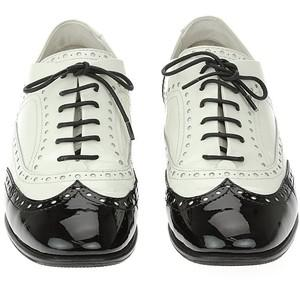

ID: 205314267 | Size: (300, 300) | Mode: RGB


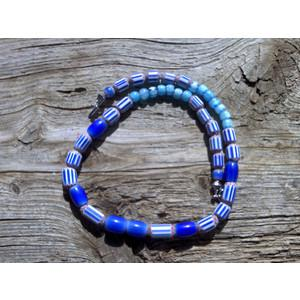

ID: 119492889 | Size: (300, 300) | Mode: RGB


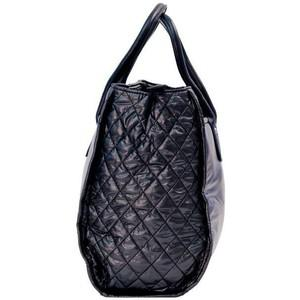

ID: 117302724 | Size: (300, 300) | Mode: RGB


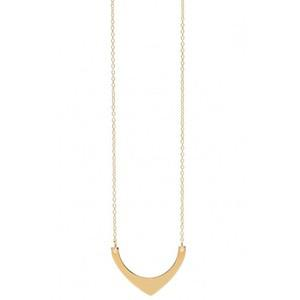

ID: 143127534 | Size: (300, 300) | Mode: RGB


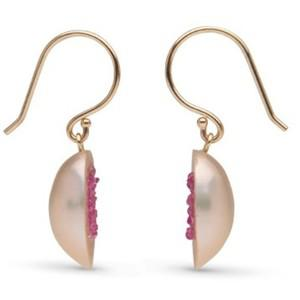

In [40]:
from PIL import Image
import random

# Pick 5 random usable items
sample_ids = random.sample(usable_ids, 5)

for item_id in sample_ids:
    image_path = os.path.join(IMAGE_DIR, f"{item_id}.jpg")
    
    img = Image.open(image_path)
    
    print(
        f"ID: {item_id} | "
        f"Size: {img.size} | "
        f"Mode: {img.mode}"
    )
    
    display(img)

In [41]:
from collections import Counter

sizes = Counter()

for item_id in usable_ids[:1000]:
    image_path = os.path.join(IMAGE_DIR, f"{item_id}.jpg")
    
    with Image.open(image_path) as img:
        sizes[img.size] += 1

print("Different image sizes:", len(sizes))
print("\nMost common sizes:")

for size, count in sizes.most_common(10):
    print(size, "→", count)

Different image sizes: 1

Most common sizes:
(300, 300) → 1000


Item ID: 100004189
Image path: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/100004189.jpg
Semantic category: sunglasses
Title: 
Description: 


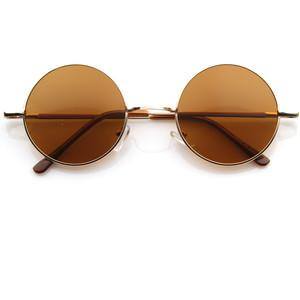

In [42]:
item_id = usable_ids[0]

# Get metadata
item = metadata_df.loc[item_id]

# Get image path
image_path = os.path.join(IMAGE_DIR, f"{item_id}.jpg")

print("Item ID:", item_id)
print("Image path:", image_path)
print("Semantic category:", item["semantic_category"])
print("Title:", item["title"])
print("Description:", item["description"])

display(Image.open(image_path))

# FashionCLIP


In [43]:
!pip install fashion-clip -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 16.2 MB/s eta 0:00:0000:01
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.7/44.7 kB 1.7 MB/s eta 0:00:00


In [44]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)

PyTorch: 2.10.0+cu128
Transformers: 5.0.0


In [45]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected")

CUDA available: True
GPU: Tesla T4


In [46]:
from transformers import CLIPModel, CLIPProcessor

print("CLIP is available!")

CLIP is available!


In [47]:
import os

# Search common Kaggle locations for anything containing "fashion" or "clip"
for root in ["/kaggle/input", "/kaggle/models"]:
    if os.path.exists(root):
        print(f"\n--- {root} ---")
        for name in os.listdir(root)[:50]:
            print(name)


--- /kaggle/input ---
datasets


In [48]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [49]:
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "patrickjohncyh/fashion-clip"

processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

print("Device:", device)
print("FashionCLIP loaded!")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

The image processor of type `CLIPImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/568 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: patrickjohncyh/fashion-clip
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Device: cuda
FashionCLIP loaded!


In [50]:
import os

EMBED_DIR = "/kaggle/working/fashion_embeddings"
os.makedirs(EMBED_DIR, exist_ok=True)

print("Embedding folder:", EMBED_DIR)

Embedding folder: /kaggle/working/fashion_embeddings


In [51]:
import numpy as np

embeddings = np.load(
    "/kaggle/input/datasets/ibtissamejabir/embadding/image_embeddings.npy",
    mmap_mode="r"
)

image_ids = np.load(
    "/kaggle/input/datasets/ibtissamejabir/image-ids-npy/image_ids.npy"
)

In [52]:
query_id = "100004189"

query_index = list(image_ids).index(query_id)

query_embedding = embeddings[query_index]

similarities = embeddings @ query_embedding

top_indices = np.argsort(similarities)[::-1][1:11]

for rank, index in enumerate(top_indices, start=1):
    item_id = image_ids[index]

    category = metadata_df.loc[item_id, "semantic_category"]
    similarity = similarities[index]

    print(
        f"Rank {rank} | "
        f"{item_id} | "
        f"{category} | "
        f"{similarity:.3f}"
    )

Rank 1 | 83877712 | sunglasses | 0.993
Rank 2 | 58890724 | sunglasses | 0.976
Rank 3 | 62842801 | sunglasses | 0.949
Rank 4 | 71239595 | sunglasses | 0.941
Rank 5 | 80755605 | sunglasses | 0.939
Rank 6 | 92153950 | sunglasses | 0.938
Rank 7 | 152540750 | sunglasses | 0.936
Rank 8 | 133672409 | sunglasses | 0.935
Rank 9 | 204323377 | sunglasses | 0.933
Rank 10 | 86479298 | sunglasses | 0.930


In [54]:
import numpy as np
import os

EMBED_DIR = "/kaggle/working/fashion_embeddings"

embeddings = np.load(
    os.path.join(EMBED_DIR, "image_embeddings.npy"),
    mmap_mode="r"
)

image_ids = np.load(
    os.path.join(EMBED_DIR, "image_ids.npy")
)

print("Embeddings shape:", embeddings.shape)
print("Number of image IDs:", len(image_ids))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/working/fashion_embeddings/image_embeddings.npy'

In [55]:
query = "black leather sneakers"

text_inputs = processor(
    text=query,
    return_tensors="pt",
    padding=True
)

text_inputs = {
    key: value.to(device)
    for key, value in text_inputs.items()
}

with torch.no_grad():

    text_outputs = model.text_model(
        input_ids=text_inputs["input_ids"],
        attention_mask=text_inputs["attention_mask"]
    )

    text_pooled = text_outputs.pooler_output

    text_features = model.text_projection(
        text_pooled
    )

    text_features = text_features / text_features.norm(
        dim=-1,
        keepdim=True
    )

print("Text embedding shape:", text_features.shape)
print("Text embedding norm:", text_features.norm(dim=-1))

Text embedding shape: torch.Size([1, 512])
Text embedding norm: tensor([1.0000], device='cuda:0')


In [56]:
# Convert text embedding from GPU → NumPy
text_embedding = text_features.cpu().numpy()[0]

# Compare text with every fashion image
similarities = embeddings @ text_embedding

# Get top 10 results
top_k = 10

top_indices = np.argsort(similarities)[::-1][:top_k]

# Display results
for rank, index in enumerate(top_indices, start=1):

    item_id = str(image_ids[index])

    category = metadata_df.loc[item_id, "semantic_category"]

    similarity = similarities[index]

    print(
        f"Rank {rank} | "
        f"{item_id} | "
        f"{category} | "
        f"{similarity:.3f}"
    )

Rank 1 | 157192445 | shoes | 0.346
Rank 2 | 195326928 | shoes | 0.344
Rank 3 | 182796047 | shoes | 0.342
Rank 4 | 214185629 | shoes | 0.337
Rank 5 | 156366041 | shoes | 0.337
Rank 6 | 181635034 | shoes | 0.337
Rank 7 | 170502157 | shoes | 0.336
Rank 8 | 190629595 | shoes | 0.336
Rank 9 | 183869473 | shoes | 0.336
Rank 10 | 162919978 | shoes | 0.332


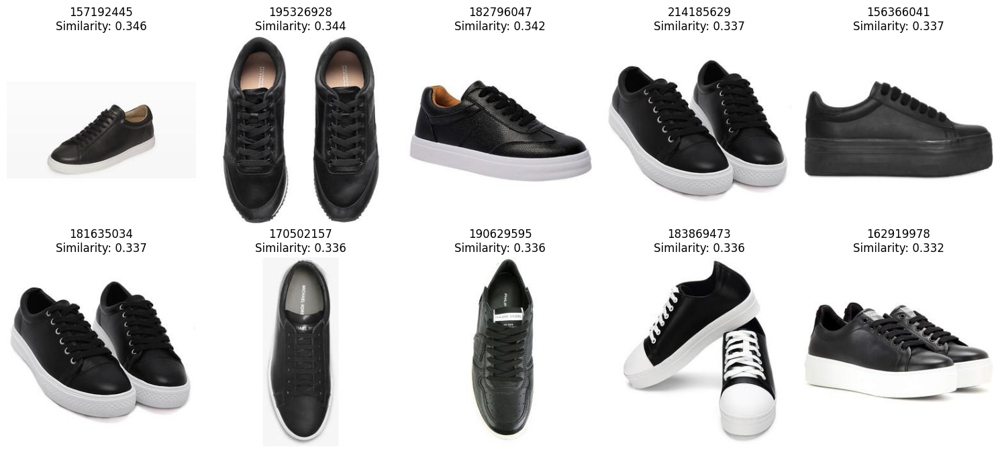

In [57]:
import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 7)
)

for ax, index in zip(axes.flatten(), top_indices):

    item_id = str(image_ids[index])

    image_path = os.path.join(
        IMAGE_DIR,
        f"{item_id}.jpg"
    )

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)

    ax.set_title(
        f"{item_id}\nSimilarity: {similarities[index]:.3f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [58]:
def search_fashion(query, top_k=10):

    # Convert text query into a FashionCLIP embedding
    text_inputs = processor(
        text=query,
        return_tensors="pt",
        padding=True
    )

    text_inputs = {
        key: value.to(device)
        for key, value in text_inputs.items()
    }

    # Generate text embedding
    with torch.no_grad():

        text_outputs = model.text_model(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs["attention_mask"]
        )

        text_pooled = text_outputs.pooler_output

        text_features = model.text_projection(
            text_pooled
        )

        # Normalize
        text_features = text_features / text_features.norm(
            dim=-1,
            keepdim=True
        )

    # Move query embedding to CPU / NumPy
    text_embedding = text_features.cpu().numpy()[0]

    # Compare query with all image embeddings
    similarities = embeddings @ text_embedding

    # Get top results
    top_indices = np.argsort(similarities)[::-1][:top_k]

    results = []

    for index in top_indices:

        item_id = str(image_ids[index])

        results.append({
            "item_id": item_id,
            "category": metadata_df.loc[
                item_id,
                "semantic_category"
            ],
            "similarity": float(similarities[index])
        })

    return results

In [59]:
results = search_fashion(
    "black leather sneakers",
    top_k=10
)

results

[{'item_id': '157192445',
  'category': 'shoes',
  'similarity': 0.3463740348815918},
 {'item_id': '195326928',
  'category': 'shoes',
  'similarity': 0.3443359136581421},
 {'item_id': '182796047',
  'category': 'shoes',
  'similarity': 0.3420085608959198},
 {'item_id': '214185629',
  'category': 'shoes',
  'similarity': 0.33735907077789307},
 {'item_id': '156366041',
  'category': 'shoes',
  'similarity': 0.3372392952442169},
 {'item_id': '181635034',
  'category': 'shoes',
  'similarity': 0.3369055986404419},
 {'item_id': '170502157',
  'category': 'shoes',
  'similarity': 0.33625897765159607},
 {'item_id': '190629595',
  'category': 'shoes',
  'similarity': 0.3360324203968048},
 {'item_id': '183869473',
  'category': 'shoes',
  'similarity': 0.33589085936546326},
 {'item_id': '162919978',
  'category': 'shoes',
  'similarity': 0.33201709389686584}]

In [60]:
results = search_fashion(
    "red summer dress",
    top_k=10
)

results

[{'item_id': '144445894',
  'category': 'all-body',
  'similarity': 0.36463090777397156},
 {'item_id': '160457855',
  'category': 'all-body',
  'similarity': 0.36227720975875854},
 {'item_id': '154578329',
  'category': 'all-body',
  'similarity': 0.35614830255508423},
 {'item_id': '172631819',
  'category': 'all-body',
  'similarity': 0.35144832730293274},
 {'item_id': '172884595',
  'category': 'all-body',
  'similarity': 0.3445912003517151},
 {'item_id': '193007222',
  'category': 'all-body',
  'similarity': 0.3439689874649048},
 {'item_id': '132689944',
  'category': 'all-body',
  'similarity': 0.3435654044151306},
 {'item_id': '210125542',
  'category': 'all-body',
  'similarity': 0.34257087111473083},
 {'item_id': '171861275',
  'category': 'all-body',
  'similarity': 0.3424443006515503},
 {'item_id': '174107853',
  'category': 'all-body',
  'similarity': 0.3422830104827881}]

In [61]:
queries = [
    "black dress",
    "white dress",
    "red dress",
    "blue dress"
]

for query in queries:

    results = search_fashion(
        query,
        top_k=5
    )

    print("\n", query)

    for result in results:
        print(
            result["item_id"],
            result["similarity"]
        )


 black dress
173627419 0.3491849899291992
195516477 0.34884113073349
59470786 0.347897469997406
193369779 0.3473500907421112
189401835 0.34220951795578003

 white dress
193774591 0.34327512979507446
169954791 0.34229451417922974
208264107 0.342035174369812
192753067 0.3386928141117096
55643062 0.33767592906951904

 red dress
160457855 0.3464512825012207
90931027 0.34596335887908936
84768620 0.34412795305252075
181547901 0.34390005469322205
86385298 0.34194615483283997

 blue dress
210492743 0.35132890939712524
104039576 0.35081374645233154
213292636 0.34694886207580566
165698897 0.3460422158241272
208873459 0.3454115092754364


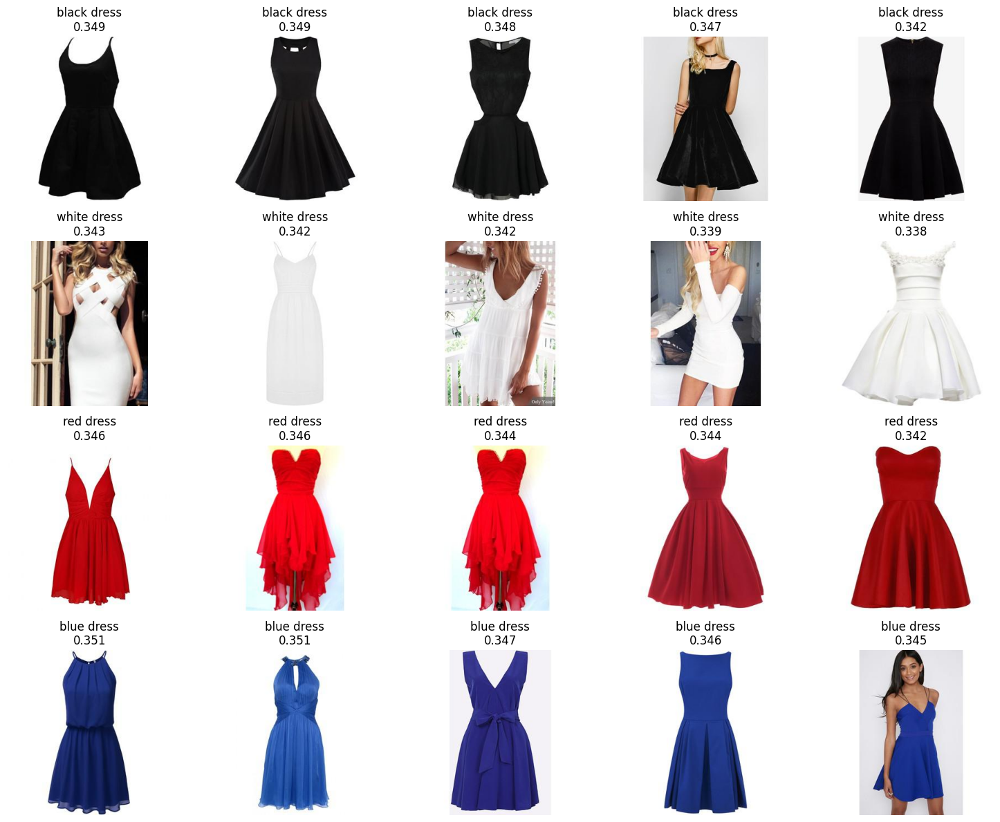

In [62]:
import matplotlib.pyplot as plt
from PIL import Image
import os

queries = [
    "black dress",
    "white dress",
    "red dress",
    "blue dress"
]

fig, axes = plt.subplots(
    4, 5,
    figsize=(15, 12)
)

for row, query in enumerate(queries):

    results = search_fashion(query, top_k=5)

    for col, result in enumerate(results):

        item_id = result["item_id"]

        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        ax = axes[row, col]

        ax.imshow(image)

        ax.set_title(
            f"{query}\n{result['similarity']:.3f}"
        )

        ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
def search_fashion(query, top_k=10):
    """
    Retrieve the most visually relevant fashion items
    for a text query using FashionCLIP.
    """

    # 1. Convert text into a FashionCLIP embedding
    text_inputs = processor(
        text=query,
        return_tensors="pt",
        padding=True
    )

    text_inputs = {
        key: value.to(device)
        for key, value in text_inputs.items()
    }

    with torch.no_grad():

        text_outputs = model.text_model(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs["attention_mask"]
        )

        text_pooled = text_outputs.pooler_output

        text_features = model.text_projection(
            text_pooled
        )

        # Normalize so dot product = cosine similarity
        text_features = text_features / text_features.norm(
            dim=-1,
            keepdim=True
        )

    text_embedding = text_features.cpu().numpy()[0]

    # 2. Compare query against all fashion image embeddings
    similarities = embeddings @ text_embedding

    # 3. Get the most similar items
    top_indices = np.argsort(similarities)[::-1][:top_k]

    # 4. Build clean results
    results = []

    for index in top_indices:

        item_id = str(image_ids[index])

        results.append({
            "item_id": item_id,
            "category": metadata_df.loc[
                item_id,
                "semantic_category"
            ],
            "similarity": float(similarities[index]),
            "image_path": os.path.join(
                IMAGE_DIR,
                f"{item_id}.jpg"
            )
        })

    return results

In [64]:
results = search_fashion(
    "black leather sneakers",
    top_k=10
)

for result in results:
    print(result)

{'item_id': '157192445', 'category': 'shoes', 'similarity': 0.3463740348815918, 'image_path': '/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/157192445.jpg'}
{'item_id': '195326928', 'category': 'shoes', 'similarity': 0.3443359136581421, 'image_path': '/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/195326928.jpg'}
{'item_id': '182796047', 'category': 'shoes', 'similarity': 0.3420085608959198, 'image_path': '/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/182796047.jpg'}
{'item_id': '214185629', 'category': 'shoes', 'similarity': 0.33735907077789307, 'image_path': '/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/214185629.jpg'}
{'item_id': '156366041', 'category': 'shoes', 'similarity': 0.3372392952442169, 'image_path': '/kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/im

In [65]:
import matplotlib.pyplot as plt
from PIL import Image


def show_results(results, cols=5):
    rows = (len(results) + cols - 1) // cols

    plt.figure(figsize=(15, 3 * rows))

    for i, result in enumerate(results):

        image = Image.open(result["image_path"])

        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            f'{result["category"]}\n'
            f'{result["similarity"]:.3f}',
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

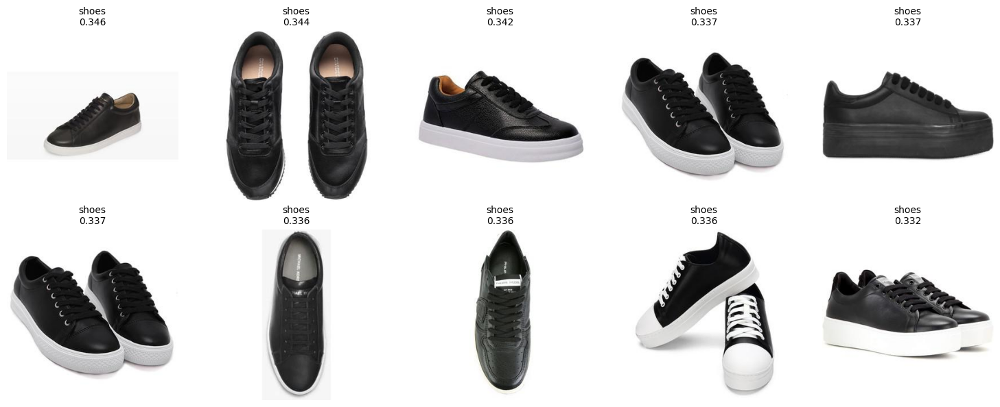

In [66]:
results = search_fashion(
    "black leather sneakers",
    top_k=10
)

show_results(results)

In [67]:
results = search_fashion(
    "black leather sneakers",
    top_k=10
)

for rank, result in enumerate(results, start=1):
    print(
        f"Rank {rank} | "
        f"{result['item_id']} | "
        f"{result['category']} | "
        f"{result['similarity']:.3f}"
    )

Rank 1 | 157192445 | shoes | 0.346
Rank 2 | 195326928 | shoes | 0.344
Rank 3 | 182796047 | shoes | 0.342
Rank 4 | 214185629 | shoes | 0.337
Rank 5 | 156366041 | shoes | 0.337
Rank 6 | 181635034 | shoes | 0.337
Rank 7 | 170502157 | shoes | 0.336
Rank 8 | 190629595 | shoes | 0.336
Rank 9 | 183869473 | shoes | 0.336
Rank 10 | 162919978 | shoes | 0.332


In [68]:
TRAIN_PATH = os.path.join(DATA_DIR, "train.txt")

with open(TRAIN_PATH, "r") as f:
    train_lines = f.readlines()

print("Number of lines:", len(train_lines))

print("\nFirst 10 lines:\n")
for line in train_lines[:10]:
    print(line.strip())

Number of lines: 40288

First 10 lines:

/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/191986825.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/204241660.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/213551955.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/195495184.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/208946292.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/200803565.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/165670920.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/140035079.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/154625931.jpg
/content/dataset/polyvore-outfit-dataset/polyvore_outfits/images/191561085.jpg


In [69]:
LABELS_DIR = os.path.join(DATA_DIR, "labels")

print("Number of files:", len(os.listdir(LABELS_DIR)))

print("\nFirst 20 files:")
for filename in os.listdir(LABELS_DIR)[:20]:
    print(filename)

Number of files: 141061

First 20 files:
181836949.txt
207568771.txt
135649465.txt
131244523.txt
150963071.txt
106219922.txt
213487524.txt
199428097.txt
74500896.txt
119599198.txt
206634636.txt
209251485.txt
155318834.txt
205683120.txt
69851359.txt
215322195.txt
145038078.txt
189280726.txt
151535344.txt
184370481.txt


In [70]:
label_file = os.path.join(
    LABELS_DIR,
    "181836949.txt"
)

with open(label_file, "r") as f:
    content = f.read()

print(content)

0 0.506667 0.500000 0.906667 1.000000


In [71]:
NONDISJOINT_DIR = os.path.join(DATA_DIR, "nondisjoint")

print("Number of files:", len(os.listdir(NONDISJOINT_DIR)))

print("\nFirst 20 files:")
for filename in os.listdir(NONDISJOINT_DIR)[:20]:
    print(filename)

Number of files: 10

First 20 files:
train.json
compatibility_test.txt
test.json
fill_in_blank_train.json
compatibility_train.txt
typespaces.p
fill_in_blank_test.json
compatibility_valid.txt
valid.json
fill_in_blank_valid.json


In [72]:
COMPAT_TRAIN_PATH = os.path.join(
    NONDISJOINT_DIR,
    "compatibility_train.txt"
)

with open(COMPAT_TRAIN_PATH, "r") as f:
    compatibility_train = f.readlines()

print("Number of lines:", len(compatibility_train))

print("\nFirst 10 lines:\n")

for line in compatibility_train[:10]:
    print(line.strip())

Number of lines: 106612

First 10 lines:

1 210750761_1 210750761_2 210750761_3
1 217602530_1 217602530_2 217602530_3 217602530_4 217602530_5 217602530_6
1 221884093_1 221884093_2 221884093_3
1 202131990_1 202131990_2 202131990_3 202131990_4
1 224733539_1 224733539_2 224733539_3 224733539_4 224733539_5
1 205854806_1 205854806_2 205854806_3 205854806_4 205854806_5 205854806_6
1 171276574_1 171276574_2 171276574_3 171276574_4
1 223431903_1 223431903_2 223431903_3 223431903_4 223431903_5 223431903_6
1 222100710_1 222100710_2
1 225336909_1 225336909_2 225336909_3


In [73]:
from collections import Counter

labels = []

for line in compatibility_train:
    parts = line.strip().split()

    if parts:
        labels.append(parts[0])

print(Counter(labels))

Counter({'1': 53306, '0': 53306})


In [74]:
outfit_line = compatibility_train[1].strip()

print("Line:")
print(outfit_line)

items = outfit_line.split()[1:]

print("\nItems:")
for item in items:
    print(item)

Line:
1 217602530_1 217602530_2 217602530_3 217602530_4 217602530_5 217602530_6

Items:
217602530_1
217602530_2
217602530_3
217602530_4
217602530_5
217602530_6


In [75]:
outfit_id = "217602530"

matches = [
    item_id
    for item_id in image_ids
    if str(item_id).startswith(outfit_id)
]

print("Matching image IDs:")
print(matches)

Matching image IDs:
[]


In [76]:
TRAIN_JSON_PATH = os.path.join(
    NONDISJOINT_DIR,
    "train.json"
)

with open(TRAIN_JSON_PATH, "r") as f:
    train_json = json.load(f)

print(type(train_json))

if isinstance(train_json, dict):
    print("Number of entries:", len(train_json))
    print("\nFirst entry:")
    first_key = next(iter(train_json))
    print(first_key)
    print(train_json[first_key])

elif isinstance(train_json, list):
    print("Number of entries:", len(train_json))
    print("\nFirst entry:")
    print(train_json[0])

<class 'list'>
Number of entries: 53306

First entry:
{'items': [{'item_id': '154249722', 'index': 1}, {'item_id': '188425631', 'index': 2}, {'item_id': '183214727', 'index': 3}], 'set_id': '210750761'}


In [77]:
first = train_json[0]

print("JSON set_id:", first["set_id"])

print("\nJSON items:")
for item in first["items"]:
    print(
        "index:", item["index"],
        "| item_id:", item["item_id"]
    )

print("\nCompatibility line:")
print(compatibility_train[0].strip())

JSON set_id: 210750761

JSON items:
index: 1 | item_id: 154249722
index: 2 | item_id: 188425631
index: 3 | item_id: 183214727

Compatibility line:
1 210750761_1 210750761_2 210750761_3


In [78]:
embedding_id_set = set(str(x) for x in image_ids)

missing_items = []

for outfit in train_json:
    for item in outfit["items"]:
        item_id = item["item_id"]

        if item_id not in embedding_id_set:
            missing_items.append(item_id)

print("Total item references:", sum(len(x["items"]) for x in train_json))
print("Missing from embeddings:", len(missing_items))

Total item references: 284767
Missing from embeddings: 0


In [79]:
for line in compatibility_train:
    if line.startswith("0 "):
        print(line.strip())
        break

0  68998648_2 197242653_4 208581771_4


In [80]:
negative_items = [
    ("68998648", 2),
    ("197242653", 4),
    ("208581771", 4)
]

for set_id, index in negative_items:

    matches = [
        outfit
        for outfit in train_json
        if outfit["set_id"] == set_id
    ]

    print(f"\nSet ID: {set_id}")

    if matches:
        outfit = matches[0]

        print("Items:")
        for item in outfit["items"]:
            print(
                "index:", item["index"],
                "| item_id:", item["item_id"]
            )
    else:
        print("NOT FOUND")


Set ID: 68998648
Items:
index: 1 | item_id: 57552892
index: 2 | item_id: 62948080
index: 3 | item_id: 70979379
index: 4 | item_id: 73039303
index: 5 | item_id: 71635063

Set ID: 197242653
Items:
index: 1 | item_id: 169929565
index: 2 | item_id: 170669931
index: 3 | item_id: 170671414
index: 4 | item_id: 170672086

Set ID: 208581771
Items:
index: 1 | item_id: 133857301
index: 2 | item_id: 185171863
index: 3 | item_id: 181162451
index: 4 | item_id: 163584044


In [81]:
from collections import Counter

positive_sizes = []
negative_sizes = []

for line in compatibility_train:

    parts = line.strip().split()

    label = parts[0]
    num_items = len(parts) - 1

    if label == "1":
        positive_sizes.append(num_items)
    else:
        negative_sizes.append(num_items)

print("Positive outfit sizes:")
print(Counter(positive_sizes))

print("\nNegative outfit sizes:")
print(Counter(negative_sizes))

Positive outfit sizes:
Counter({5: 14271, 6: 11304, 4: 10655, 7: 6479, 3: 4741, 8: 2981, 9: 1171, 2: 1057, 10: 407, 11: 145, 12: 57, 13: 15, 14: 12, 16: 4, 17: 3, 15: 3, 19: 1})

Negative outfit sizes:
Counter({5: 14271, 6: 11304, 4: 10655, 7: 6479, 3: 4741, 8: 2981, 9: 1171, 2: 1057, 10: 407, 11: 145, 12: 57, 13: 15, 14: 12, 16: 4, 17: 3, 15: 3, 19: 1})


In [82]:
# Create a lookup:
# ("set_id", item index) → actual item_id

outfit_item_lookup = {}

for outfit in train_json:
    set_id = outfit["set_id"]

    for item in outfit["items"]:
        index = item["index"]
        item_id = item["item_id"]

        outfit_item_lookup[(set_id, index)] = item_id

print("Number of mappings:", len(outfit_item_lookup))

# Test one mapping
print(
    "Test:",
    outfit_item_lookup[("210750761", 1)]
)

Number of mappings: 284767
Test: 154249722


In [83]:
for line in compatibility_train[:5]:

    parts = line.strip().split()

    # First value = compatibility label
    label = int(parts[0])

    # Everything after the label = item references
    references = parts[1:]

    # Convert references to real image/item IDs
    item_ids = []

    for ref in references:
        set_id, index = ref.rsplit("_", 1)
        index = int(index)

        item_id = outfit_item_lookup[(set_id, index)]
        item_ids.append(item_id)

    print("Label:", label)
    print("References:", references)
    print("Item IDs:", item_ids)
    print()

Label: 1
References: ['210750761_1', '210750761_2', '210750761_3']
Item IDs: ['154249722', '188425631', '183214727']

Label: 1
References: ['217602530_1', '217602530_2', '217602530_3', '217602530_4', '217602530_5', '217602530_6']
Item IDs: ['201813350', '195213892', '169020872', '194628844', '196672591', '185367365']

Label: 1
References: ['221884093_1', '221884093_2', '221884093_3']
Item IDs: ['201799451', '194990026', '203786992']

Label: 1
References: ['202131990_1', '202131990_2', '202131990_3', '202131990_4']
Item IDs: ['165668728', '171568733', '175018750', '176086342']

Label: 1
References: ['224733539_1', '224733539_2', '224733539_3', '224733539_4', '224733539_5']
Item IDs: ['214359927', '209892020', '214483399', '214249851', '214249489']



In [84]:
# Find the first negative example
for line in compatibility_train:
    if line.strip().startswith("0"):
        parts = line.strip().split()

        label = int(parts[0])
        references = parts[1:]

        item_ids = []

        for ref in references:
            set_id, index = ref.rsplit("_", 1)
            index = int(index)

            item_id = outfit_item_lookup[(set_id, index)]
            item_ids.append(item_id)

        print("Label:", label)
        print("References:", references)
        print("Item IDs:", item_ids)

        break

Label: 0
References: ['68998648_2', '197242653_4', '208581771_4']
Item IDs: ['62948080', '170672086', '163584044']


In [85]:
import matplotlib.pyplot as plt

def show_outfit(item_ids, title):
    plt.figure(figsize=(15, 4))

    for i, item_id in enumerate(item_ids):
        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        plt.subplot(1, len(item_ids), i + 1)
        plt.imshow(image)
        plt.axis("off")
        plt.title(str(item_id))

    plt.suptitle(title)
    plt.show()

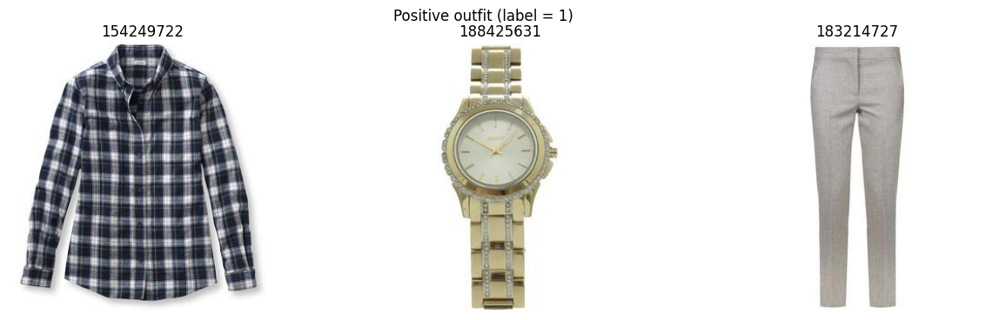

In [86]:
positive_item_ids = [
    "154249722",
    "188425631",
    "183214727"
]

show_outfit(
    positive_item_ids,
    "Positive outfit (label = 1)"
)

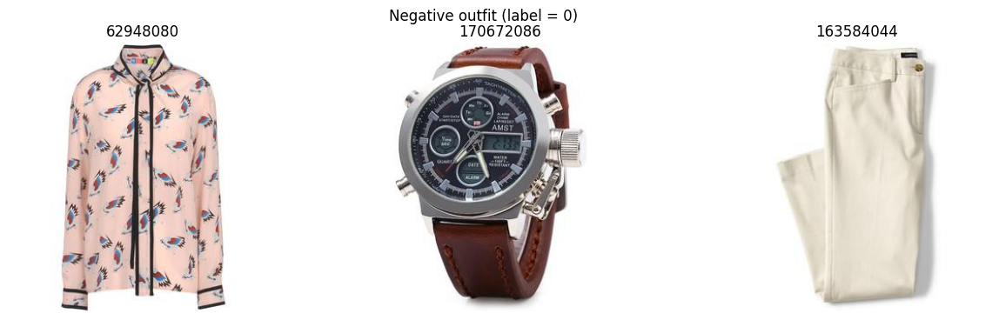

In [87]:
negative_item_ids = [
    "62948080",
    "170672086",
    "163584044"
]

show_outfit(
    negative_item_ids,
    "Negative outfit (label = 0)"
)

In [88]:
import numpy as np

outfit_sizes = []

for line in compatibility_train:
    parts = line.strip().split()

    # Don't count the label
    num_items = len(parts) - 1

    outfit_sizes.append(num_items)

print("Minimum items:", min(outfit_sizes))
print("Maximum items:", max(outfit_sizes))
print("Average items:", np.mean(outfit_sizes))
print("Median items:", np.median(outfit_sizes))

Minimum items: 2
Maximum items: 19
Average items: 5.342119086031591
Median items: 5.0


In [89]:
from collections import Counter

size_counts = Counter(outfit_sizes)

for size in sorted(size_counts):
    print(
        f"{size} items: {size_counts[size]:,} examples"
    )

2 items: 2,114 examples
3 items: 9,482 examples
4 items: 21,310 examples
5 items: 28,542 examples
6 items: 22,608 examples
7 items: 12,958 examples
8 items: 5,962 examples
9 items: 2,342 examples
10 items: 814 examples
11 items: 290 examples
12 items: 114 examples
13 items: 30 examples
14 items: 24 examples
15 items: 6 examples
16 items: 8 examples
17 items: 6 examples
19 items: 2 examples


In [90]:
COMPAT_VALID_PATH = os.path.join(
    NONDISJOINT_DIR,
    "compatibility_valid.txt"
)

with open(COMPAT_VALID_PATH, "r") as f:
    compatibility_valid = f.readlines()

print("Number of validation examples:", len(compatibility_valid))

print("\nFirst 3 examples:")
for line in compatibility_valid[:3]:
    print(line.strip())

Number of validation examples: 10000

First 3 examples:
1 224930161_1 224930161_2 224930161_3 224930161_4
1 208756998_1 208756998_2 208756998_3 208756998_4 208756998_5
1 218698690_1 218698690_2 218698690_3 218698690_4 218698690_5 218698690_6 218698690_7 218698690_8


In [91]:
COMPAT_TEST_PATH = os.path.join(
    NONDISJOINT_DIR,
    "compatibility_test.txt"
)

with open(COMPAT_TEST_PATH, "r") as f:
    compatibility_test = f.readlines()

print("Number of test examples:", len(compatibility_test))

print("\nFirst 3 examples:")
for line in compatibility_test[:3]:
    print(line.strip())

Number of test examples: 20000

First 3 examples:
1 217320763_1 217320763_2 217320763_3 217320763_4
1 221590515_1 221590515_2 221590515_3 221590515_4 221590515_5
1 42911078_1 42911078_2 42911078_3 42911078_4 42911078_5 42911078_6 42911078_7


In [92]:
from collections import Counter

valid_labels = []

for line in compatibility_valid:
    parts = line.strip().split()

    if parts:
        valid_labels.append(int(parts[0]))

print(Counter(valid_labels))

Counter({1: 5000, 0: 5000})


In [93]:
test_labels = []

for line in compatibility_test:
    parts = line.strip().split()

    if parts:
        test_labels.append(int(parts[0]))

print(Counter(test_labels))

Counter({1: 10000, 0: 10000})


In [94]:
def prepare_compatibility_example(line):
    parts = line.strip().split()

    # First value is the label
    label = int(parts[0])

    # Remaining values are references such as 210750761_1
    references = parts[1:]

    item_ids = []

    for ref in references:
        set_id, index = ref.rsplit("_", 1)
        index = int(index)

        item_id = outfit_item_lookup[(set_id, index)]
        item_ids.append(item_id)

    # Convert item IDs to FashionCLIP embeddings
    item_embeddings = np.stack([
        embeddings[id_to_index[item_id]]
        for item_id in item_ids
    ])

    return label, item_ids, item_embeddings

In [95]:
id_to_index = {
    str(item_id): index
    for index, item_id in enumerate(image_ids)
}

print("Number of indexed items:", len(id_to_index))

Number of indexed items: 251008


In [96]:
label, item_ids, item_embeddings = prepare_compatibility_example(
    compatibility_train[0]
)

print("Label:", label)
print("Item IDs:", item_ids)
print("Embedding shape:", item_embeddings.shape)

Label: 1
Item IDs: ['154249722', '188425631', '183214727']
Embedding shape: (3, 512)


In [97]:
import torch
from torch.utils.data import Dataset


class OutfitCompatibilityDataset(Dataset):

    def __init__(self, compatibility_lines):
        self.lines = compatibility_lines

    def __len__(self):
        return len(self.lines)

    def __getitem__(self, index):
        line = self.lines[index]

        label, item_ids, item_embeddings = (
            prepare_compatibility_example(line)
        )

        return (
            torch.tensor(item_embeddings, dtype=torch.float32),
            torch.tensor(label, dtype=torch.float32)
        )

In [98]:
train_dataset = OutfitCompatibilityDataset(
    compatibility_train
)

print("Training examples:", len(train_dataset))

Training examples: 106612


In [99]:
# Test a few different training examples

for i in [0, 1, 2, 100, 1000]:

    item_embeddings, label = train_dataset[i]

    print(
        f"Example {i} | "
        f"Items: {item_embeddings.shape[0]} | "
        f"Embedding size: {item_embeddings.shape[1]} | "
        f"Label: {int(label.item())}"
    )

Example 0 | Items: 3 | Embedding size: 512 | Label: 1
Example 1 | Items: 6 | Embedding size: 512 | Label: 1
Example 2 | Items: 3 | Embedding size: 512 | Label: 1
Example 100 | Items: 5 | Embedding size: 512 | Label: 1
Example 1000 | Items: 6 | Embedding size: 512 | Label: 1


In [100]:
def outfit_collate_fn(batch):

    embeddings_list = [item[0] for item in batch]
    labels = torch.stack([item[1] for item in batch])

    # Number of items in the largest outfit in this batch
    max_items = max(
        embeddings.shape[0]
        for embeddings in embeddings_list
    )

    batch_size = len(embeddings_list)

    # Create zero-padding
    padded_embeddings = torch.zeros(
        batch_size,
        max_items,
        512,
        dtype=torch.float32
    )

    # True = real item
    # False = padding
    attention_mask = torch.zeros(
        batch_size,
        max_items,
        dtype=torch.bool
    )

    for i, embeddings in enumerate(embeddings_list):

        num_items = embeddings.shape[0]

        padded_embeddings[
            i,
            :num_items
        ] = embeddings

        attention_mask[
            i,
            :num_items
        ] = True

    return padded_embeddings, attention_mask, labels

In [101]:
# Get three examples with different numbers of items
example_batch = [
    train_dataset[0],
    train_dataset[1],
    train_dataset[100]
]

padded_embeddings, attention_mask, labels = (
    outfit_collate_fn(example_batch)
)

print("Padded embeddings shape:", padded_embeddings.shape)
print("Attention mask shape:", attention_mask.shape)
print("Labels shape:", labels.shape)

print("\nAttention mask:")
print(attention_mask)

print("\nLabels:")
print(labels)

Padded embeddings shape: torch.Size([3, 6, 512])
Attention mask shape: torch.Size([3, 6])
Labels shape: torch.Size([3])

Attention mask:
tensor([[ True,  True,  True, False, False, False],
        [ True,  True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True, False]])

Labels:
tensor([1., 1., 1.])


In [102]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=outfit_collate_fn
)

print("Number of batches:", len(train_loader))

Number of batches: 3332


In [103]:
batch_embeddings, batch_mask, batch_labels = next(iter(train_loader))

print("Embeddings:", batch_embeddings.shape)
print("Mask:", batch_mask.shape)
print("Labels:", batch_labels.shape)

print("\nNumber of real items in first 5 outfits:")

for i in range(5):
    print(
        f"Outfit {i}:",
        batch_mask[i].sum().item(),
        "items | Label:",
        int(batch_labels[i].item())
    )

Embeddings: torch.Size([32, 9, 512])
Mask: torch.Size([32, 9])
Labels: torch.Size([32])

Number of real items in first 5 outfits:
Outfit 0: 7 items | Label: 0
Outfit 1: 6 items | Label: 0
Outfit 2: 3 items | Label: 1
Outfit 3: 4 items | Label: 0
Outfit 4: 4 items | Label: 0


In [104]:
import torch.nn as nn


class OutfitCompatibilityModel(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden_dim=256,
        num_heads=4,
        num_layers=2
    ):
        super().__init__()

        # 512 → 256
        self.input_projection = nn.Linear(
            input_dim,
            hidden_dim
        )

        # Transformer learns relationships between items
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=num_heads,
            dim_feedforward=hidden_dim * 4,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Final classifier: compatible or incompatible
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 1)
        )

    def forward(self, x, attention_mask):

        # x shape:
        # [batch, items, 512]
        x = self.input_projection(x)

        # x shape:
        # [batch, items, 256]

        # Transformer expects True for positions to IGNORE,
        # while our mask uses True for REAL items.
        padding_mask = ~attention_mask

        x = self.transformer(
            x,
            src_key_padding_mask=padding_mask
        )

        # Remove padded positions from the average
        mask = attention_mask.unsqueeze(-1).float()

        x = x * mask

        summed = x.sum(dim=1)

        number_of_items = mask.sum(dim=1).clamp(min=1)

        pooled = summed / number_of_items

        # One raw compatibility score
        logits = self.classifier(pooled).squeeze(-1)

        return logits

In [105]:
model = OutfitCompatibilityModel()

print(model)

OutfitCompatibilityModel(
  (input_projection): Linear(in_features=512, out_features=256, bias=True)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
        (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_featur

In [106]:
# Test the model on one real batch

model.eval()

with torch.no_grad():
    logits = model(
        batch_embeddings,
        batch_mask
    )

print("Input shape:", batch_embeddings.shape)
print("Output shape:", logits.shape)
print("First 5 logits:", logits[:5])

Input shape: torch.Size([32, 9, 512])
Output shape: torch.Size([32])
First 5 logits: tensor([ 0.0331, -0.0340,  0.1132,  0.0617, -0.0115])


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


In [107]:
# Move model to GPU
model = model.to(device)

# Loss for binary classification
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

print("Model device:", next(model.parameters()).device)

Model device: cuda:0


In [108]:
valid_dataset = OutfitCompatibilityDataset(
    compatibility_valid
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=outfit_collate_fn
)

print("Validation examples:", len(valid_dataset))
print("Validation batches:", len(valid_loader))

Validation examples: 10000
Validation batches: 313


In [109]:
def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for embeddings_batch, mask_batch, labels_batch in data_loader:

            embeddings_batch = embeddings_batch.to(device)
            mask_batch = mask_batch.to(device)
            labels_batch = labels_batch.to(device)

            logits = model(
                embeddings_batch,
                mask_batch
            )

            loss = criterion(
                logits,
                labels_batch
            )

            total_loss += loss.item() * labels_batch.size(0)

            predictions = (torch.sigmoid(logits) >= 0.5).float()

            correct += (
                predictions == labels_batch
            ).sum().item()

            total += labels_batch.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [110]:
import json
import os

valid_json_path = os.path.join(
    DATA_DIR,
    "nondisjoint",
    "valid.json"
)

with open(valid_json_path, "r") as f:
    valid_json = json.load(f)

print("Number of validation outfits:", len(valid_json))
print("First validation outfit:")
print(valid_json[0])

Number of validation outfits: 5000
First validation outfit:
{'items': [{'item_id': '213343990', 'index': 1}, {'item_id': '206270853', 'index': 2}, {'item_id': '202059322', 'index': 3}, {'item_id': '53908391', 'index': 4}], 'set_id': '224930161'}


In [111]:
valid_item_lookup = {}

for outfit in valid_json:
    set_id = outfit["set_id"]

    for item in outfit["items"]:
        index = item["index"]
        item_id = item["item_id"]

        valid_item_lookup[(set_id, index)] = item_id

print("Number of validation mappings:", len(valid_item_lookup))

print(
    "Test:",
    valid_item_lookup[("224930161", 1)]
)

Number of validation mappings: 26781
Test: 213343990


In [112]:
def prepare_compatibility_example(line, item_lookup):
    parts = line.strip().split()

    label = int(parts[0])
    references = parts[1:]

    item_ids = []

    for ref in references:
        set_id, index = ref.rsplit("_", 1)
        index = int(index)

        item_id = item_lookup[(set_id, index)]
        item_ids.append(item_id)

    item_embeddings = np.stack([
        embeddings[id_to_index[item_id]]
        for item_id in item_ids
    ])

    return label, item_ids, item_embeddings

In [113]:
class OutfitCompatibilityDataset(Dataset):

    def __init__(self, compatibility_lines, item_lookup):
        self.lines = compatibility_lines
        self.item_lookup = item_lookup

    def __len__(self):
        return len(self.lines)

    def __getitem__(self, index):
        line = self.lines[index]

        label, item_ids, item_embeddings = (
            prepare_compatibility_example(
                line,
                self.item_lookup
            )
        )

        return (
            torch.tensor(item_embeddings, dtype=torch.float32),
            torch.tensor(label, dtype=torch.float32)
        )

In [114]:
train_dataset = OutfitCompatibilityDataset(
    compatibility_train,
    outfit_item_lookup
)

valid_dataset = OutfitCompatibilityDataset(
    compatibility_valid,
    valid_item_lookup
)

print("Training examples:", len(train_dataset))
print("Validation examples:", len(valid_dataset))

Training examples: 106612
Validation examples: 10000


In [115]:
emb, label = valid_dataset[0]

print("Embedding shape:", emb.shape)
print("Label:", label.item())

Embedding shape: torch.Size([4, 512])
Label: 1.0


In [116]:
valid_loader = DataLoader(
    valid_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=outfit_collate_fn
)

print("Validation batches:", len(valid_loader))

Validation batches: 313


In [117]:
batch_embeddings, batch_mask, batch_labels = next(iter(valid_loader))

print("Embeddings:", batch_embeddings.shape)
print("Mask:", batch_mask.shape)
print("Labels:", batch_labels.shape)

Embeddings: torch.Size([32, 11, 512])
Mask: torch.Size([32, 11])
Labels: torch.Size([32])


In [118]:
val_loss, val_accuracy = evaluate_model(
    model,
    valid_loader,
    criterion,
    device
)

print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4f}")

Validation loss: 0.6933
Validation accuracy: 0.4928


In [119]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=outfit_collate_fn
)

print("Training batches:", len(train_loader))

Training batches: 3332


In [120]:
batch_embeddings, batch_mask, batch_labels = next(iter(train_loader))

print("Embeddings:", batch_embeddings.shape)
print("Mask:", batch_mask.shape)
print("Labels:", batch_labels.shape)

Embeddings: torch.Size([32, 8, 512])
Mask: torch.Size([32, 8])
Labels: torch.Size([32])


In [121]:
EPOCHS = 3

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for embeddings_batch, mask_batch, labels_batch in train_loader:

        embeddings_batch = embeddings_batch.to(device)
        mask_batch = mask_batch.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        logits = model(
            embeddings_batch,
            mask_batch
        )

        loss = criterion(
            logits,
            labels_batch
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels_batch.size(0)

        predictions = (
            torch.sigmoid(logits) >= 0.5
        ).float()

        correct += (
            predictions == labels_batch
        ).sum().item()

        total += labels_batch.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate_model(
        model,
        valid_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 1/3 | Train Loss: 0.4971 | Train Acc: 0.7532 | Val Loss: 0.4072 | Val Acc: 0.8182
Epoch 2/3 | Train Loss: 0.3833 | Train Acc: 0.8305 | Val Loss: 0.3633 | Val Acc: 0.8408
Epoch 3/3 | Train Loss: 0.3351 | Train Acc: 0.8539 | Val Loss: 0.3450 | Val Acc: 0.8521


In [122]:
# Get one positive and one negative training example

positive_line = next(
    line for line in compatibility_train
    if line.startswith("1 ")
)

negative_line = next(
    line for line in compatibility_train
    if line.startswith("0 ")
)

pos_label, pos_ids, pos_emb = prepare_compatibility_example(
    positive_line,
    outfit_item_lookup
)

neg_label, neg_ids, neg_emb = prepare_compatibility_example(
    negative_line,
    outfit_item_lookup
)

print("Positive label:", pos_label)
print("Positive items:", pos_ids)
print("Positive shape:", pos_emb.shape)

print()

print("Negative label:", neg_label)
print("Negative items:", neg_ids)
print("Negative shape:", neg_emb.shape)

Positive label: 1
Positive items: ['154249722', '188425631', '183214727']
Positive shape: (3, 512)

Negative label: 0
Negative items: ['62948080', '170672086', '163584044']
Negative shape: (3, 512)


In [123]:
pos_mean = pos_emb.mean(axis=0)
neg_mean = neg_emb.mean(axis=0)

print("Positive mean norm:", np.linalg.norm(pos_mean))
print("Negative mean norm:", np.linalg.norm(neg_mean))

cosine_similarity = np.dot(pos_mean, neg_mean) / (
    np.linalg.norm(pos_mean) * np.linalg.norm(neg_mean)
)

print("Positive vs negative cosine similarity:", cosine_similarity)

Positive mean norm: 0.76859593
Negative mean norm: 0.7203333
Positive vs negative cosine similarity: 0.7932597


In [124]:
print("Embedding shape:", embeddings.shape)

print("First 10 values:")
print(embeddings[0][:10])

print("Min:", embeddings.min())
print("Max:", embeddings.max())
print("Mean:", embeddings.mean())
print("Non-zero values:", np.count_nonzero(embeddings))

Embedding shape: (251008, 512)
First 10 values:
[ 0.0690036   0.02095639 -0.03885994  0.00473203  0.03252668  0.00266221
 -0.01009299  0.01055341  0.0041842   0.01922571]
Min: -0.49898848
Max: 0.4976711
Mean: 0.00017243142
Non-zero values: 128516094


In [125]:
nonzero_rows = np.count_nonzero(
    np.any(embeddings != 0, axis=1)
)

print("Rows with embeddings:", nonzero_rows)
print("Total rows:", len(embeddings))

print()
print("Positive item indices:")
print([id_to_index[item_id] for item_id in pos_ids])

print()
print("Negative item indices:")
print([id_to_index[item_id] for item_id in neg_ids])

Rows with embeddings: 251008
Total rows: 251008

Positive item indices:
[64684, 137650, 123875]

Negative item indices:
[233118, 96599, 82166]


In [126]:
nonzero_indices = np.where(
    np.any(embeddings != 0, axis=1)
)[0]

print("First non-zero index:", nonzero_indices[0])
print("Last non-zero index:", nonzero_indices[-1])
print("Number of non-zero rows:", len(nonzero_indices))

First non-zero index: 0
Last non-zero index: 251007
Number of non-zero rows: 251008


In [127]:
import os
import numpy as np

EMBED_DIR = "/kaggle/working/fashion_embeddings"
os.makedirs(EMBED_DIR, exist_ok=True)

embedding_path = os.path.join(
    EMBED_DIR,
    "image_embeddings_full.npy"
)

embeddings_full = np.lib.format.open_memmap(
    embedding_path,
    mode="w+",
    dtype="float32",
    shape=(len(usable_ids), 512)
)

print("Created:", embedding_path)
print("Shape:", embeddings_full.shape)

Created: /kaggle/working/fashion_embeddings/image_embeddings_full.npy
Shape: (251008, 512)


In [128]:
print("processor:", type(processor))
print("model:", type(model))

processor: <class 'transformers.models.clip.processing_clip.CLIPProcessor'>
model: <class '__main__.OutfitCompatibilityModel'>


In [129]:
import os

cache_dir = os.path.expanduser("~/.cache/huggingface/hub")

for name in os.listdir(cache_dir):
    if "fashion" in name.lower() or "clip" in name.lower():
        print(name)

models--patrickjohncyh--fashion-clip


In [131]:
import os

CACHE_MODEL_PATH = os.path.expanduser(
    "~/.cache/huggingface/hub/models--patrickjohncyh--fashion-clip"
)

SNAPSHOT_PATH = os.path.join(
    CACHE_MODEL_PATH,
    "snapshots",
    "7e3ba62ce16b379a1ab479346b66f192e76f51b7"
)

print(os.listdir(SNAPSHOT_PATH))

['merges.txt', 'special_tokens_map.json', 'config.json', 'tokenizer.json', 'preprocessor_config.json', 'tokenizer_config.json', 'model.safetensors', 'vocab.json']


In [133]:
fashion_clip_model = CLIPModel.from_pretrained(
    SNAPSHOT_PATH,
    local_files_only=True
)

fashion_clip_model = fashion_clip_model.to(device)
fashion_clip_model.eval()

print("FashionCLIP loaded successfully.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: /root/.cache/huggingface/hub/models--patrickjohncyh--fashion-clip/snapshots/7e3ba62ce16b379a1ab479346b66f192e76f51b7
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
vision_model.embeddings.position_ids | UNEXPECTED |  | 
text_model.embeddings.position_ids   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


FashionCLIP loaded successfully.


In [134]:
from tqdm import tqdm
from PIL import Image
import os
import torch

CHUNK_SIZE = 1000

for start in tqdm(
    range(0, len(usable_ids), CHUNK_SIZE),
    desc="Generating embeddings"
):
    end = min(start + CHUNK_SIZE, len(usable_ids))

    batch_ids = usable_ids[start:end]
    batch_images = []

    for item_id in batch_ids:
        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")
        batch_images.append(image)

    inputs = processor(
        images=batch_images,
        return_tensors="pt"
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        vision_outputs = fashion_clip_model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        pooled_output = vision_outputs.pooler_output

        image_features = fashion_clip_model.visual_projection(
            pooled_output
        )

        image_features = image_features / image_features.norm(
            dim=-1,
            keepdim=True
        )

    embeddings_full[start:end] = (
        image_features.cpu().numpy()
    )

    embeddings_full.flush()

    del inputs
    del batch_images
    del vision_outputs
    del pooled_output
    del image_features

print("Finished generating embeddings.")

Generating embeddings: 100%|██████████| 252/252 [1:17:26<00:00, 18.44s/it]

Finished generating embeddings.


In [135]:
import numpy as np

print("Shape:", embeddings_full.shape)

nonzero_rows = np.count_nonzero(
    np.any(embeddings_full != 0, axis=1)
)

print("Non-zero rows:", nonzero_rows)
print("Total rows:", len(embeddings_full))

print("First row norm:", np.linalg.norm(embeddings_full[0]))
print("Last row norm:", np.linalg.norm(embeddings_full[-1]))


Shape: (251008, 512)
Non-zero rows: 251008
Total rows: 251008
First row norm: 1.0
Last row norm: 0.99999994


In [136]:
embeddings_full.flush()

print("Embeddings saved successfully.")
print("File:", embedding_path)

Embeddings saved successfully.
File: /kaggle/working/fashion_embeddings/image_embeddings_full.npy


In [137]:
ids_path_full = os.path.join(
    EMBED_DIR,
    "image_ids_full.npy"
)

np.save(
    ids_path_full,
    np.array(usable_ids)
)

print("IDs saved successfully.")
print("File:", ids_path_full)

IDs saved successfully.
File: /kaggle/working/fashion_embeddings/image_ids_full.npy


In [138]:
embeddings = embeddings_full

image_ids = np.load(
    ids_path_full
)

id_to_index = {
    str(item_id): index
    for index, item_id in enumerate(image_ids)
}

print("Embeddings:", embeddings.shape)
print("Image IDs:", len(image_ids))
print("Lookup entries:", len(id_to_index))

Embeddings: (251008, 512)
Image IDs: 251008
Lookup entries: 251008


In [139]:
# Check one positive example
positive_line = compatibility_train[0]

label, item_ids, item_embeddings = prepare_compatibility_example(
    positive_line,
    outfit_item_lookup
)

print("Label:", label)
print("Item IDs:", item_ids)
print("Embedding shape:", item_embeddings.shape)
print("Embedding norms:", np.linalg.norm(item_embeddings, axis=1))

Label: 1
Item IDs: ['154249722', '188425631', '183214727']
Embedding shape: (3, 512)
Embedding norms: [1. 1. 1.]


In [140]:
negative_line = next(
    line for line in compatibility_train
    if line.startswith("0 ")
)

label, item_ids, item_embeddings = prepare_compatibility_example(
    negative_line,
    outfit_item_lookup
)

print("Label:", label)
print("Item IDs:", item_ids)
print("Embedding shape:", item_embeddings.shape)
print("Embedding norms:", np.linalg.norm(item_embeddings, axis=1))

Label: 0
Item IDs: ['62948080', '170672086', '163584044']
Embedding shape: (3, 512)
Embedding norms: [1.         1.         0.99999994]


In [141]:
import torch
import torch.nn as nn

model = OutfitCompatibilityModel(
    input_dim=512,
    hidden_dim=256,
    num_heads=4,
    num_layers=2
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=0.01
)

print("New compatibility model created.")

New compatibility model created.


In [142]:
val_loss, val_accuracy = evaluate_model(
    model,
    valid_loader,
    criterion,
    device
)

print(f"Initial validation loss: {val_loss:.4f}")
print(f"Initial validation accuracy: {val_accuracy:.4f}")


Initial validation loss: 0.7029
Initial validation accuracy: 0.5002


In [143]:
EPOCHS = 3

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for embeddings_batch, mask_batch, labels_batch in train_loader:

        embeddings_batch = embeddings_batch.to(device)
        mask_batch = mask_batch.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad()

        logits = model(
            embeddings_batch,
            mask_batch
        )

        loss = criterion(
            logits,
            labels_batch
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels_batch.size(0)

        predictions = (
            torch.sigmoid(logits) >= 0.5
        ).float()

        correct += (
            predictions == labels_batch
        ).sum().item()

        total += labels_batch.size(0)

    train_loss = total_loss / total
    train_accuracy = correct / total

    val_loss, val_accuracy = evaluate_model(
        model,
        valid_loader,
        criterion,
        device
    )

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

Epoch 1/3 | Train Loss: 0.5244 | Train Acc: 0.7282 | Val Loss: 0.4236 | Val Acc: 0.8070
Epoch 2/3 | Train Loss: 0.3863 | Train Acc: 0.8288 | Val Loss: 0.3688 | Val Acc: 0.8368
Epoch 3/3 | Train Loss: 0.3373 | Train Acc: 0.8533 | Val Loss: 0.3371 | Val Acc: 0.8548


In [146]:
import shutil
import os

source_dir = "/kaggle/working/fashion_embeddings"
zip_path = "/kaggle/working/fashion_embeddings_backup"

shutil.make_archive(
    zip_path,
    "zip",
    source_dir
)

final_path = zip_path + ".zip"

print(final_path)
print(
    f"Size: {os.path.getsize(final_path) / (1024**3):.2f} GB"
)

/kaggle/working/fashion_embeddings_backup.zip
Size: 0.45 GB


In [147]:
from IPython.display import FileLink

FileLink(
    "/kaggle/working/fashion_embeddings_backup.zip"
)

/kaggle/working/fashion_embeddings_backup.zip

In [148]:
from IPython.display import display, HTML

display(HTML("""
<a href="/kaggle/working/fashion_embeddings_backup.zip"
   download="fashion_embeddings_backup.zip">
   Download Fashion Embeddings
</a>
"""))

In [149]:
embeddings_batch, mask_batch, labels_batch = next(iter(train_loader))

print("Batch embeddings:", embeddings_batch.shape)
print("Non-zero values:", torch.count_nonzero(embeddings_batch).item())
print("Total values:", embeddings_batch.numel())

Batch embeddings: torch.Size([32, 11, 512])
Non-zero values: 93696
Total values: 180224


In [150]:
id="save1"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_accuracy,
        "val_loss": val_loss,
    },
    "/kaggle/working/outfit_compatibility_model.pt"
)

print("Compatibility model saved.")

Compatibility model saved.


In [151]:
test_txt_path = os.path.join(
    DATA_DIR,
    "nondisjoint",
    "compatibility_test.txt"
)

test_json_path = os.path.join(
    DATA_DIR,
    "nondisjoint",
    "test.json"
)

with open(test_txt_path, "r") as f:
    compatibility_test = f.readlines()

with open(test_json_path, "r") as f:
    test_json = json.load(f)

print("Test examples:", len(compatibility_test))
print("Test outfits:", len(test_json))

Test examples: 20000
Test outfits: 10000


In [152]:
test_item_lookup = {}

for outfit in test_json:
    set_id = outfit["set_id"]

    for item in outfit["items"]:
        index = item["index"]
        item_id = item["item_id"]

        test_item_lookup[(set_id, index)] = item_id

print("Number of test mappings:", len(test_item_lookup))

# Quick check
first_test_outfit = test_json[0]
print(first_test_outfit)

Number of test mappings: 53506
{'items': [{'item_id': '193458045', 'index': 1}, {'item_id': '195937486', 'index': 2}, {'item_id': '123858646', 'index': 3}, {'item_id': '197575483', 'index': 4}], 'set_id': '217320763'}


In [153]:
test_dataset = OutfitCompatibilityDataset(
    compatibility_test,
    test_item_lookup
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    collate_fn=outfit_collate_fn
)

print("Test dataset size:", len(test_dataset))
print("Test batches:", len(test_loader))

Test dataset size: 20000
Test batches: 625


In [154]:
test_loss, test_accuracy = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.3361
Test Accuracy: 0.8541


In [155]:
def score_outfit(item_ids):
    """
    Score how compatible a group of fashion items is.

    item_ids: list of item IDs, for example:
        ["154249722", "188425631", "183214727"]
    """

    # Get the FashionCLIP embedding for each item
    item_embeddings = np.stack([
        embeddings[id_to_index[str(item_id)]]
        for item_id in item_ids
    ])

    # Convert to PyTorch tensor
    outfit_embeddings = torch.tensor(
        item_embeddings,
        dtype=torch.float32
    ).unsqueeze(0).to(device)

    # All items are real items, so no padding is needed
    attention_mask = torch.ones(
        1,
        len(item_ids),
        dtype=torch.bool
    ).to(device)

    # Predict compatibility
    model.eval()

    with torch.no_grad():
        logits = model(
            outfit_embeddings,
            attention_mask
        )

        probability = torch.sigmoid(logits).item()

    return probability

In [156]:
example_outfit = [
    "154249722",
    "188425631",
    "183214727"
]

score = score_outfit(example_outfit)

print(f"Compatibility score: {score:.4f}")

Compatibility score: 0.7442


In [157]:
negative_test_line = next(
    line for line in compatibility_test
    if line.startswith("0 ")
)

label, negative_item_ids, _ = prepare_compatibility_example(
    negative_test_line,
    test_item_lookup
)

negative_score = score_outfit(negative_item_ids)

print("Negative outfit item IDs:", negative_item_ids)
print(f"Compatibility score: {negative_score:.4f}")

Negative outfit item IDs: ['126884451', '205229354', '175589381', '27028511']
Compatibility score: 0.1076


In [158]:
def show_outfit_items(item_ids):
    rows = []

    for item_id in item_ids:
        row = metadata_df.loc[str(item_id)]

        rows.append({
            "item_id": str(item_id),
            "title": row["title"],
            "description": row["description"],
            "semantic_category": row["semantic_category"]
        })

    return pd.DataFrame(rows)

In [159]:
show_outfit_items(negative_item_ids)

,item_id,title,description,semantic_category
0,126884451,,,bags
1,205229354,,,shoes
2,175589381,,,jewellery
3,27028511,,,all-body


In [160]:
def retrieve_candidates(query, top_k=20):
    text_inputs = processor(
        text=query,
        return_tensors="pt",
        padding=True
    )

    text_inputs = {
        key: value.to(device)
        for key, value in text_inputs.items()
    }

    with torch.no_grad():
        text_outputs = fashion_clip_model.text_model(
            input_ids=text_inputs["input_ids"],
            attention_mask=text_inputs["attention_mask"]
        )

        text_pooled = text_outputs.pooler_output

        text_features = fashion_clip_model.text_projection(
            text_pooled
        )

        text_features = text_features / text_features.norm(
            dim=-1,
            keepdim=True
        )

    text_embedding = text_features.cpu().numpy()[0]

    similarities = embeddings @ text_embedding

    top_indices = np.argsort(similarities)[::-1][:top_k]

    candidates = []

    for index in top_indices:
        item_id = str(image_ids[index])

        candidates.append({
            "item_id": item_id,
            "category": metadata_df.loc[
                item_id,
                "semantic_category"
            ],
            "similarity": float(similarities[index])
        })

    return candidates

In [161]:
candidates = retrieve_candidates(
    "black leather jacket",
    top_k=10
)

pd.DataFrame(candidates)

,item_id,category,similarity
0,213504911,outerwear,0.351737
1,172162612,outerwear,0.349674
2,132542893,outerwear,0.347904
3,87149043,outerwear,0.347482
4,156451894,outerwear,0.347196
5,72762882,outerwear,0.347032
6,111646196,outerwear,0.346978
7,57688835,outerwear,0.346930
8,81575588,outerwear,0.345835
9,201996429,outerwear,0.345289


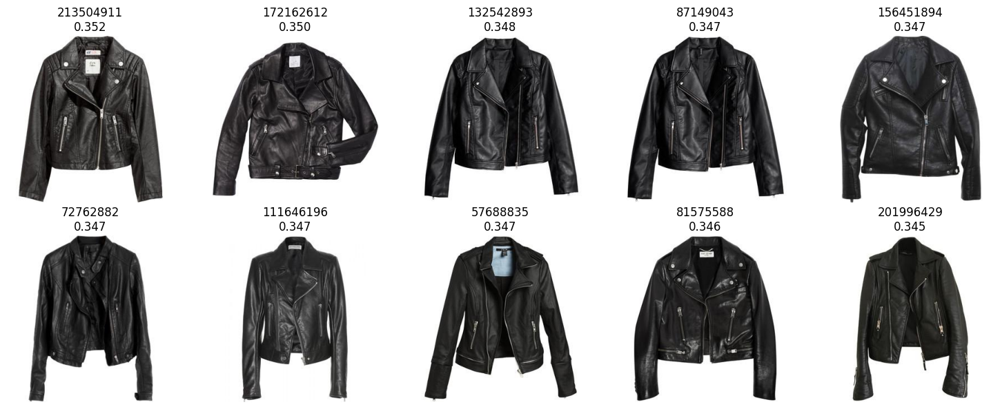

In [162]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 5,
    figsize=(15, 6)
)

for ax, candidate in zip(
    axes.flat,
    candidates
):
    item_id = candidate["item_id"]

    image_path = os.path.join(
        IMAGE_DIR,
        f"{item_id}.jpg"
    )

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        f"{item_id}\n"
        f"{candidate['similarity']:.3f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [163]:
queries = [
    "black leather jacket",
    "white top",
    "black jeans",
    "white sneakers",
    "black handbag"
]

for query in queries:

    results = retrieve_candidates(
        query,
        top_k=3
    )

    print(f"\n{query}")
    print("-" * 40)

    for result in results:
        print(
            result["item_id"],
            "|",
            result["category"],
            "|",
            round(result["similarity"], 4)
        )


black leather jacket
----------------------------------------
213504911 | outerwear | 0.3517
172162612 | outerwear | 0.3497
132542893 | outerwear | 0.3479

white top
----------------------------------------
126343766 | tops | 0.3492
130087090 | tops | 0.3463
150021909 | tops | 0.3463

black jeans
----------------------------------------
123524655 | bottoms | 0.3589
113090695 | bottoms | 0.3549
174816216 | bottoms | 0.3535

white sneakers
----------------------------------------
168944874 | shoes | 0.3533
206402772 | shoes | 0.346
170486665 | shoes | 0.3456

black handbag
----------------------------------------
139496298 | bags | 0.3511
94204617 | bags | 0.3492
182490497 | bags | 0.3471


In [164]:
category_queries = {
    "outerwear": "black leather jacket",
    "tops": "white top",
    "bottoms": "black jeans",
    "shoes": "white sneakers",
    "bags": "black handbag"
}

category_candidates = {}

for category, query in category_queries.items():

    results = retrieve_candidates(
        query,
        top_k=3
    )

    category_candidates[category] = results

    print(f"\n{category}")
    for result in results:
        print(
            result["item_id"],
            "|",
            round(result["similarity"], 4)
        )


outerwear
213504911 | 0.3517
172162612 | 0.3497
132542893 | 0.3479

tops
126343766 | 0.3492
130087090 | 0.3463
150021909 | 0.3463

bottoms
123524655 | 0.3589
113090695 | 0.3549
174816216 | 0.3535

shoes
168944874 | 0.3533
206402772 | 0.346
170486665 | 0.3456

bags
139496298 | 0.3511
94204617 | 0.3492
182490497 | 0.3471


In [165]:
from itertools import product

category_order = [
    "outerwear",
    "tops",
    "bottoms",
    "shoes",
    "bags"
]

outfit_combinations = []

for combination in product(
    *[
        category_candidates[category]
        for category in category_order
    ]
):

    item_ids = [
        item["item_id"]
        for item in combination
    ]

    retrieval_score = np.mean([
        item["similarity"]
        for item in combination
    ])

    outfit_combinations.append({
        "item_ids": item_ids,
        "retrieval_score": retrieval_score
    })

print("Number of outfit combinations:", len(outfit_combinations))

Number of outfit combinations: 243


In [166]:
ranked_outfits = []

for outfit in outfit_combinations:

    compatibility_score = score_outfit(
        outfit["item_ids"]
    )

    ranked_outfits.append({
        "item_ids": outfit["item_ids"],
        "retrieval_score": outfit["retrieval_score"],
        "compatibility_score": compatibility_score
    })

# Sort by compatibility
ranked_outfits = sorted(
    ranked_outfits,
    key=lambda x: x["compatibility_score"],
    reverse=True
)

print("Top 10 outfits:")

for i, outfit in enumerate(ranked_outfits[:10], 1):

    print(
        f"{i}. "
        f"Compatibility: {outfit['compatibility_score']:.4f} | "
        f"Retrieval: {outfit['retrieval_score']:.4f} | "
        f"Items: {outfit['item_ids']}"
    )

Top 10 outfits:
1. Compatibility: 0.9216 | Retrieval: 0.3489 | Items: ['132542893', '126343766', '113090695', '170486665', '182490497']
2. Compatibility: 0.9198 | Retrieval: 0.3486 | Items: ['132542893', '126343766', '174816216', '170486665', '182490497']
3. Compatibility: 0.9184 | Retrieval: 0.3497 | Items: ['132542893', '126343766', '123524655', '170486665', '182490497']
4. Compatibility: 0.9111 | Retrieval: 0.3484 | Items: ['132542893', '130087090', '113090695', '170486665', '182490497']
5. Compatibility: 0.9101 | Retrieval: 0.3495 | Items: ['132542893', '126343766', '174816216', '170486665', '139496298']
6. Compatibility: 0.9081 | Retrieval: 0.3481 | Items: ['132542893', '130087090', '174816216', '170486665', '182490497']
7. Compatibility: 0.9068 | Retrieval: 0.3498 | Items: ['213504911', '126343766', '174816216', '170486665', '94204617']
8. Compatibility: 0.9060 | Retrieval: 0.3492 | Items: ['132542893', '130087090', '123524655', '170486665', '182490497']
9. Compatibility: 0.9050 

In [167]:
retrieval_scores = np.array([
    outfit["retrieval_score"]
    for outfit in ranked_outfits
])

compatibility_scores = np.array([
    outfit["compatibility_score"]
    for outfit in ranked_outfits
])

# Min-max normalization
retrieval_min = retrieval_scores.min()
retrieval_max = retrieval_scores.max()

compatibility_min = compatibility_scores.min()
compatibility_max = compatibility_scores.max()

for outfit in ranked_outfits:

    retrieval_normalized = (
        outfit["retrieval_score"] - retrieval_min
    ) / (
        retrieval_max - retrieval_min + 1e-8
    )

    compatibility_normalized = (
        outfit["compatibility_score"] - compatibility_min
    ) / (
        compatibility_max - compatibility_min + 1e-8
    )

    outfit["final_score"] = (
        0.4 * retrieval_normalized
        + 0.6 * compatibility_normalized
    )

ranked_outfits = sorted(
    ranked_outfits,
    key=lambda x: x["final_score"],
    reverse=True
)

for i, outfit in enumerate(ranked_outfits[:10], 1):

    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f} | "
        f"Retrieval: {outfit['retrieval_score']:.4f}"
    )

1. Final: 0.7655 | Compatibility: 0.8724 | Retrieval: 0.3521
2. Final: 0.7499 | Compatibility: 0.9050 | Retrieval: 0.3505
3. Final: 0.7390 | Compatibility: 0.8462 | Retrieval: 0.3528
4. Final: 0.7285 | Compatibility: 0.9184 | Retrieval: 0.3497
5. Final: 0.7195 | Compatibility: 0.8498 | Retrieval: 0.3525
6. Final: 0.7168 | Compatibility: 0.8779 | Retrieval: 0.3513
7. Final: 0.7148 | Compatibility: 0.8855 | Retrieval: 0.3509
8. Final: 0.7095 | Compatibility: 0.8915 | Retrieval: 0.3506
9. Final: 0.7028 | Compatibility: 0.8728 | Retrieval: 0.3513
10. Final: 0.6971 | Compatibility: 0.9068 | Retrieval: 0.3498


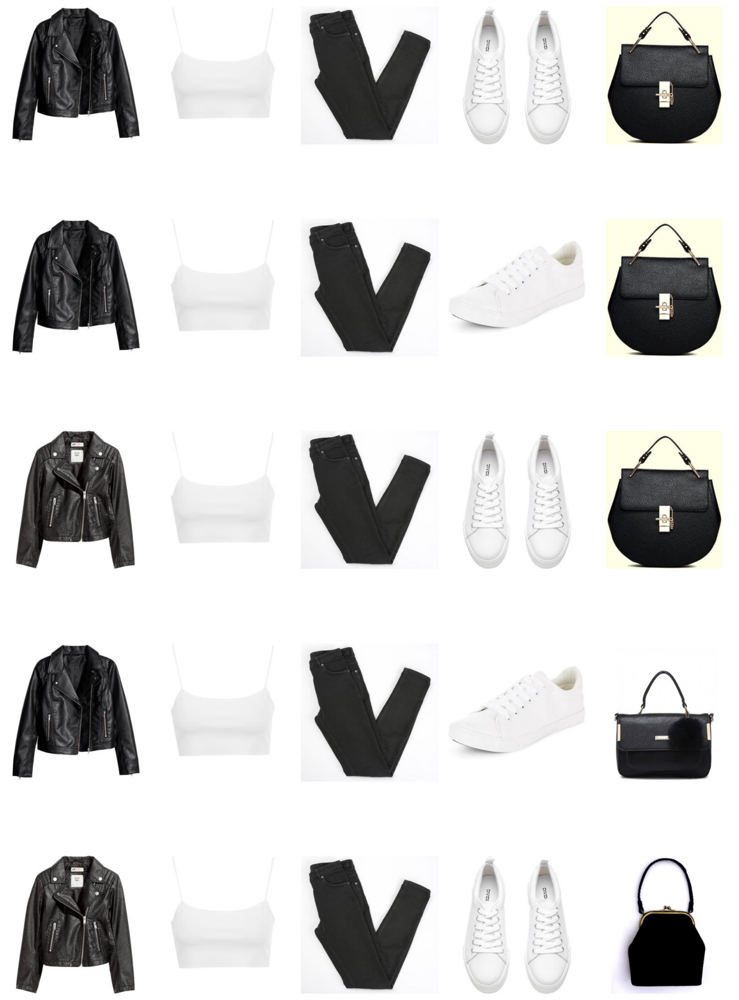

In [168]:
import matplotlib.pyplot as plt

top_outfits = ranked_outfits[:5]

fig, axes = plt.subplots(
    5,
    5,
    figsize=(12, 18)
)

for row, outfit in enumerate(top_outfits):

    for col, item_id in enumerate(outfit["item_ids"]):

        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"#{row + 1}\n"
        f"Final: {outfit['final_score']:.3f}\n"
        f"Compat: {outfit['compatibility_score']:.3f}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [169]:
def recommend_outfits(
    queries,
    candidates_per_category=3,
    top_k=5
):
    """
    Generate and rank complete outfits.

    queries should contain:
        outerwear
        tops
        bottoms
        shoes
        bags
    """

    # 1. Retrieve candidates
    category_candidates = {}

    for category, query in queries.items():

        category_candidates[category] = retrieve_candidates(
            query,
            top_k=candidates_per_category
        )

    # 2. Create combinations
    category_order = [
        "outerwear",
        "tops",
        "bottoms",
        "shoes",
        "bags"
    ]

    combinations = []

    for combination in product(
        *[
            category_candidates[category]
            for category in category_order
        ]
    ):

        item_ids = [
            item["item_id"]
            for item in combination
        ]

        retrieval_score = np.mean([
            item["similarity"]
            for item in combination
        ])

        combinations.append({
            "item_ids": item_ids,
            "retrieval_score": retrieval_score
        })

    # 3. Score compatibility
    results = []

    for outfit in combinations:

        compatibility_score = score_outfit(
            outfit["item_ids"]
        )

        results.append({
            "item_ids": outfit["item_ids"],
            "retrieval_score": outfit["retrieval_score"],
            "compatibility_score": compatibility_score
        })

    # 4. Normalize scores
    retrieval_scores = np.array([
        x["retrieval_score"]
        for x in results
    ])

    compatibility_scores = np.array([
        x["compatibility_score"]
        for x in results
    ])

    retrieval_min = retrieval_scores.min()
    retrieval_max = retrieval_scores.max()

    compatibility_min = compatibility_scores.min()
    compatibility_max = compatibility_scores.max()

    for outfit in results:

        retrieval_normalized = (
            outfit["retrieval_score"] - retrieval_min
        ) / (
            retrieval_max - retrieval_min + 1e-8
        )

        compatibility_normalized = (
            outfit["compatibility_score"] - compatibility_min
        ) / (
            compatibility_max - compatibility_min + 1e-8
        )

        outfit["final_score"] = (
            0.3 * retrieval_normalized
            + 0.7 * compatibility_normalized
        )

    # 5. Rank
    results = sorted(
        results,
        key=lambda x: x["final_score"],
        reverse=True
    )

    return results[:top_k]

In [170]:
recommendation_queries = {
    "outerwear": "black leather jacket",
    "tops": "white top",
    "bottoms": "black jeans",
    "shoes": "white sneakers",
    "bags": "black handbag"
}

recommendations = recommend_outfits(
    recommendation_queries,
    candidates_per_category=3,
    top_k=5
)

for i, outfit in enumerate(recommendations, 1):

    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])
    print()

1. Final: 0.7917 | Compatibility: 0.9184
Items: ['132542893', '126343766', '123524655', '170486665', '182490497']

2. Final: 0.7884 | Compatibility: 0.9050
Items: ['132542893', '126343766', '123524655', '170486665', '139496298']

3. Final: 0.7554 | Compatibility: 0.9216
Items: ['132542893', '126343766', '113090695', '170486665', '182490497']

4. Final: 0.7532 | Compatibility: 0.8724
Items: ['132542893', '126343766', '123524655', '168944874', '139496298']

5. Final: 0.7514 | Compatibility: 0.9068
Items: ['213504911', '126343766', '174816216', '170486665', '94204617']



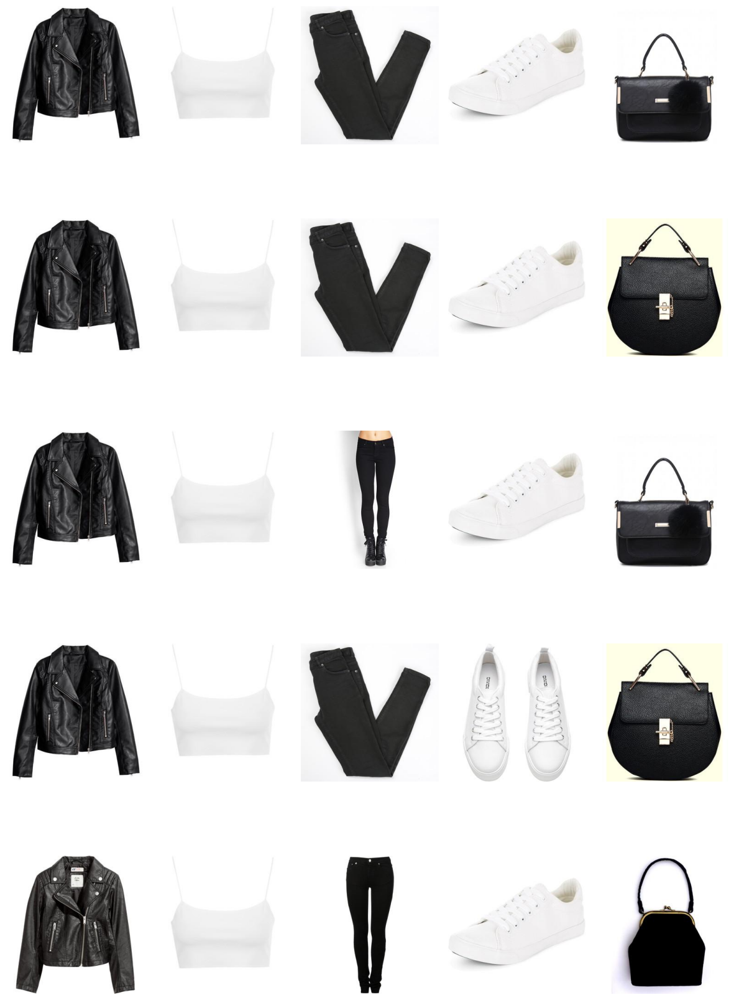

In [171]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    5,
    5,
    figsize=(12, 18)
)

for row, outfit in enumerate(recommendations):

    for col, item_id in enumerate(outfit["item_ids"]):

        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"#{row + 1}\n"
        f"Score: {outfit['final_score']:.3f}\n"
        f"Compat: {outfit['compatibility_score']:.3f}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [172]:
def build_category_queries(
    style,
    colors,
    occasion
):
    queries = {
        "outerwear": f"{colors} {style} jacket",
        "tops": f"{colors} {style} top",
        "bottoms": f"{colors} {style} pants",
        "shoes": f"{colors} {style} shoes",
        "bags": f"{colors} {style} bag"
    }

    return queries

In [173]:
queries = build_category_queries(
    style="casual",
    colors="black and white",
    occasion="everyday"
)

queries

{'outerwear': 'black and white casual jacket',
 'tops': 'black and white casual top',
 'bottoms': 'black and white casual pants',
 'shoes': 'black and white casual shoes',
 'bags': 'black and white casual bag'}

In [174]:
def build_category_queries(
    style,
    colors,
    occasion
):
    queries = {
        "outerwear": f"{style} jacket, {colors}",
        "tops": f"{style} top, {colors}",
        "bottoms": f"{style} pants, {colors}",
        "shoes": f"{style} shoes, {colors}",
        "bags": f"{style} bag, {colors}"
    }

    return queries

In [175]:
queries = build_category_queries(
    style="casual",
    colors="black and white",
    occasion="everyday"
)

for category, query in queries.items():
    print(category, "→", query)

outerwear → casual jacket, black and white
tops → casual top, black and white
bottoms → casual pants, black and white
shoes → casual shoes, black and white
bags → casual bag, black and white


In [176]:
def generate_recommendations(
    style,
    colors,
    occasion,
    candidates_per_category=3,
    top_k=5
):
    # Build category-specific queries
    queries = build_category_queries(
        style=style,
        colors=colors,
        occasion=occasion
    )

    # Generate and rank outfits
    recommendations = recommend_outfits(
        queries,
        candidates_per_category=candidates_per_category,
        top_k=top_k
    )

    return recommendations

In [177]:
recommendations = generate_recommendations(
    style="casual",
    colors="black and white",
    occasion="everyday"
)

for i, outfit in enumerate(recommendations, 1):

    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])
    print()

1. Final: 0.9603 | Compatibility: 0.9885
Items: ['143882436', '187959705', '176290787', '209711081', '142886711']

2. Final: 0.9498 | Compatibility: 0.9885
Items: ['143882436', '187959705', '141908848', '209711081', '142886711']

3. Final: 0.9448 | Compatibility: 0.9895
Items: ['143882436', '138754654', '176290787', '209711081', '142886711']

4. Final: 0.9371 | Compatibility: 0.9880
Items: ['170164196', '187959705', '176290787', '209711081', '142886711']

5. Final: 0.9343 | Compatibility: 0.9895
Items: ['143882436', '138754654', '141908848', '209711081', '142886711']



In [178]:
def parse_user_request(text):

    text = text.lower()

    # Detect style
    styles = [
        "casual",
        "formal",
        "elegant",
        "sporty",
        "streetwear",
        "vintage"
    ]

    detected_style = None

    for style in styles:
        if style in text:
            detected_style = style
            break

    # Detect occasion
    occasions = [
        "everyday",
        "work",
        "party",
        "date",
        "wedding",
        "gym",
        "travel"
    ]

    detected_occasion = None

    for occasion in occasions:
        if occasion in text:
            detected_occasion = occasion
            break

    # Detect colors
    colors = [
        "black",
        "white",
        "red",
        "blue",
        "green",
        "pink",
        "beige",
        "brown",
        "gray",
        "grey"
    ]

    detected_colors = [
        color for color in colors
        if color in text
    ]

    return {
        "style": detected_style,
        "colors": " and ".join(detected_colors),
        "occasion": detected_occasion
    }

In [179]:
request = parse_user_request(
    "I want a casual black and white outfit for everyday wear."
)

request

{'style': 'casual', 'colors': 'black and white', 'occasion': 'everyday'}

In [180]:
def recommend_from_text(
    text,
    candidates_per_category=3,
    top_k=5
):
    # 1. Understand the request
    preferences = parse_user_request(text)

    # 2. Generate category queries
    queries = build_category_queries(
        style=preferences["style"],
        colors=preferences["colors"],
        occasion=preferences["occasion"]
    )

    # 3. Generate outfit recommendations
    recommendations = recommend_outfits(
        queries,
        candidates_per_category=candidates_per_category,
        top_k=top_k
    )

    return preferences, recommendations
    

In [181]:
text = "I want a casual black and white outfit for everyday wear."

preferences, recommendations = recommend_from_text(text)

print("Detected preferences:")
print(preferences)

print("\nRecommendations:")

for i, outfit in enumerate(recommendations, 1):

    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])
    print()

Detected preferences:
{'style': 'casual', 'colors': 'black and white', 'occasion': 'everyday'}

Recommendations:
1. Final: 0.9603 | Compatibility: 0.9885
Items: ['143882436', '187959705', '176290787', '209711081', '142886711']

2. Final: 0.9498 | Compatibility: 0.9885
Items: ['143882436', '187959705', '141908848', '209711081', '142886711']

3. Final: 0.9448 | Compatibility: 0.9895
Items: ['143882436', '138754654', '176290787', '209711081', '142886711']

4. Final: 0.9371 | Compatibility: 0.9880
Items: ['170164196', '187959705', '176290787', '209711081', '142886711']

5. Final: 0.9343 | Compatibility: 0.9895
Items: ['143882436', '138754654', '141908848', '209711081', '142886711']



In [182]:
def build_category_queries(
    style=None,
    colors=None,
    occasion=None
):
    # Use safe defaults when something is missing
    style_text = style if style else "fashionable"
    color_text = colors if colors else "any color"

    queries = {
        "outerwear": f"{style_text} jacket, {color_text}",
        "tops": f"{style_text} top, {color_text}",
        "bottoms": f"{style_text} pants, {color_text}",
        "shoes": f"{style_text} shoes, {color_text}",
        "bags": f"{style_text} bag, {color_text}"
    }

    return queries

In [183]:
request = parse_user_request(
    "I want a casual outfit for everyday wear."
)

print(request)

queries = build_category_queries(
    style=request["style"],
    colors=request["colors"],
    occasion=request["occasion"]
)

for category, query in queries.items():
    print(category, "→", query)

{'style': 'casual', 'colors': '', 'occasion': 'everyday'}
outerwear → casual jacket, any color
tops → casual top, any color
bottoms → casual pants, any color
shoes → casual shoes, any color
bags → casual bag, any color


In [184]:
def create_preference_prompt(user_request):

    prompt = f"""
You are a fashion recommendation assistant.

Extract the following information from the user's request:

- style
- colors
- occasion
- clothing_preferences

User request:
"{user_request}"

Return the information in this exact format:

style: <style or none>
colors: <colors or none>
occasion: <occasion or none>
clothing_preferences: <important clothing details or none>
"""

    return prompt

In [185]:
prompt = create_preference_prompt(
    "I want a casual black and white outfit for everyday wear."
)

print(prompt)


You are a fashion recommendation assistant.

Extract the following information from the user's request:

- style
- colors
- occasion
- clothing_preferences

User request:
"I want a casual black and white outfit for everyday wear."

Return the information in this exact format:

style: <style or none>
colors: <colors or none>
occasion: <occasion or none>
clothing_preferences: <important clothing details or none>



In [186]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)

llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    torch_dtype=torch.float16,
    device_map="auto"
)

llm.eval()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 1536)
    (layers): ModuleList(
      (0-27): 28 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=1536, out_features=1536, bias=True)
          (k_proj): Linear(in_features=1536, out_features=256, bias=True)
          (v_proj): Linear(in_features=1536, out_features=256, bias=True)
          (o_proj): Linear(in_features=1536, out_features=1536, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (up_proj): Linear(in_features=1536, out_features=8960, bias=False)
          (down_proj): Linear(in_features=8960, out_features=1536, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((1536,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((1536,), eps=1e-06)
    (rotar

In [187]:
def extract_preferences_with_llm(user_request):

    prompt = f"""
You are a fashion recommendation assistant.

Extract the following information from the user's request:

- style
- colors
- occasion
- clothing_preferences

User request:
"{user_request}"

Return ONLY these four lines:

style: <style or none>
colors: <colors or none>
occasion: <occasion or none>
clothing_preferences: <important clothing details or none>
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [188]:
response = extract_preferences_with_llm(
    "I want a casual black and white outfit for everyday wear."
)

print(response)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


style: Casual
colors: Black, White
occasion: Everyday Wear
clothing_preferences: None specified


In [189]:
test_requests = [
    "I need an elegant outfit for a dinner date. I prefer dark colors and I don't want anything too revealing.",
    
    "Give me a sporty outfit for the gym, preferably something comfortable in blue or black.",
    
    "I want something feminine and classy for a wedding. I like beige, cream, and soft pink."
]

for request in test_requests:

    print("=" * 70)
    print("USER:", request)
    print()

    response = extract_preferences_with_llm(request)

    print(response)
    print()

USER: I need an elegant outfit for a dinner date. I prefer dark colors and I don't want anything too revealing.

style: Elegant
colors: Dark
occasion: Dinner Date
clothing_preferences: Prefer not to be too revealing

USER: Give me a sporty outfit for the gym, preferably something comfortable in blue or black.

style: Sporty
colors: Blue, Black
occasion: Gym
clothing_preferences: Comfortable

USER: I want something feminine and classy for a wedding. I like beige, cream, and soft pink.

style: Feminine and classy
colors: Beige, Cream, Soft Pink
occasion: Wedding
clothing_preferences: None specified



In [190]:
def extract_preferences_with_llm(user_request):

    prompt = f"""
You are a fashion recommendation assistant.

Analyze the user's fashion request and extract:

1. style
2. colors
3. occasion
4. clothing_preferences

Rules:
- style must be a short string.
- colors must be a JSON list of colors.
- occasion must be a short string.
- clothing_preferences must be a JSON list.
- If something is not specified, use an empty string or empty list.
- Return ONLY valid JSON.
- Do not add explanations.

User request:
"{user_request}"

Return exactly this structure:

{{
    "style": "",
    "colors": [],
    "occasion": "",
    "clothing_preferences": []
}}
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [191]:
request = "Give me a sporty outfit for the gym, preferably something comfortable in blue or black."

response = extract_preferences_with_llm(request)

print(response)

```json
{
    "style": "",
    "colors": [],
    "occasion": "gym",
    "clothing_preferences": ["comfortable"]
}
```


In [192]:
def extract_preferences_with_llm(user_request):

    prompt = f"""
You are a fashion recommendation assistant.

Analyze the user's request and extract the information exactly from the text.

IMPORTANT:
- Do not omit information that is explicitly stated.
- Keep descriptive style words such as casual, elegant, sporty,
  feminine, classy, vintage, streetwear, etc.
- Extract every explicitly mentioned color.
- Extract the occasion.
- Extract important clothing preferences such as comfortable,
  modest, not revealing, loose, fitted, oversized, etc.
- Do not invent information that the user did not mention.

Return ONLY valid JSON.

Required format:

{{
    "style": "",
    "colors": [],
    "occasion": "",
    "clothing_preferences": []
}}

User request:
"{user_request}"
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [193]:
request = "Give me a sporty outfit for the gym, preferably something comfortable in blue or black."

response = extract_preferences_with_llm(request)

print(response)

{
    "style": "sporty",
    "colors": ["blue", "black"],
    "occasion": "gym",
    "clothing_preferences": ["comfortable"]
}


In [194]:
import json

def parse_llm_preferences(response):

    preferences = json.loads(response)

    return preferences

In [195]:
response = extract_preferences_with_llm(
    "Give me a sporty outfit for the gym, preferably something comfortable in blue or black."
)

preferences = parse_llm_preferences(response)

print(preferences)
print(type(preferences))

{'style': 'sporty', 'colors': ['blue', 'black'], 'occasion': 'gym', 'clothing_preferences': ['comfortable']}
<class 'dict'>


In [196]:
def build_category_queries_from_preferences(preferences):

    style = preferences.get("style", "")
    colors = preferences.get("colors", [])
    occasion = preferences.get("occasion", "")
    clothing_preferences = preferences.get(
        "clothing_preferences",
        []
    )

    # Convert lists into text
    color_text = ", ".join(colors)
    preference_text = ", ".join(clothing_preferences)

    # Safe defaults
    style_text = style if style else "fashionable"
    color_text = color_text if color_text else "any color"
    preference_text = (
        preference_text
        if preference_text
        else ""
    )

    queries = {
        "outerwear": (
            f"{style_text} jacket "
            f"{color_text} "
            f"{preference_text}"
        ),

        "tops": (
            f"{style_text} top "
            f"{color_text} "
            f"{preference_text}"
        ),

        "bottoms": (
            f"{style_text} pants "
            f"{color_text} "
            f"{preference_text}"
        ),

        "shoes": (
            f"{style_text} shoes "
            f"{color_text} "
            f"{preference_text}"
        ),

        "bags": (
            f"{style_text} bag "
            f"{color_text} "
            f"{preference_text}"
        )
    }

    # Clean extra spaces
    queries = {
        category: " ".join(query.split())
        for category, query in queries.items()
    }

    return queries

In [197]:
queries = build_category_queries_from_preferences(
    preferences
)

for category, query in queries.items():
    print(category, "→", query)

outerwear → sporty jacket blue, black comfortable
tops → sporty top blue, black comfortable
bottoms → sporty pants blue, black comfortable
shoes → sporty shoes blue, black comfortable
bags → sporty bag blue, black comfortable


In [198]:
def build_category_queries_from_preferences(preferences):

    style = preferences.get("style", "")
    colors = preferences.get("colors", [])
    occasion = preferences.get("occasion", "")
    clothing_preferences = preferences.get(
        "clothing_preferences",
        []
    )

    color_text = ", ".join(colors)
    preference_text = ", ".join(clothing_preferences)

    style_text = style if style else "fashionable"
    color_text = color_text if color_text else "any color"
    occasion_text = occasion if occasion else ""
    preference_text = preference_text if preference_text else ""

    queries = {
        "outerwear": (
            f"{style_text} {occasion_text} jacket "
            f"{color_text} {preference_text}"
        ),

        "tops": (
            f"{style_text} {occasion_text} top "
            f"{color_text} {preference_text}"
        ),

        "bottoms": (
            f"{style_text} {occasion_text} pants "
            f"{color_text} {preference_text}"
        ),

        "shoes": (
            f"{style_text} {occasion_text} shoes "
            f"{color_text} {preference_text}"
        ),

        "bags": (
            f"{style_text} {occasion_text} bag "
            f"{color_text} {preference_text}"
        )
    }

    # Remove duplicate spaces
    queries = {
        category: " ".join(query.split())
        for category, query in queries.items()
    }

    return queries

In [199]:
queries = build_category_queries_from_preferences(
    preferences
)

for category, query in queries.items():
    print(category, "→", query)

outerwear → sporty gym jacket blue, black comfortable
tops → sporty gym top blue, black comfortable
bottoms → sporty gym pants blue, black comfortable
shoes → sporty gym shoes blue, black comfortable
bags → sporty gym bag blue, black comfortable


In [200]:
recommendations = recommend_outfits(
    queries,
    candidates_per_category=3,
    top_k=5
)

for i, outfit in enumerate(recommendations, 1):

    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])
    print()

1. Final: 0.9584 | Compatibility: 0.9730
Items: ['180939179', '169628419', '42538338', '202527828', '194620245']

2. Final: 0.9351 | Compatibility: 0.9509
Items: ['180939179', '169628419', '42538338', '202527828', '182395426']

3. Final: 0.9334 | Compatibility: 0.9798
Items: ['138213035', '169628419', '42538338', '202527828', '194620245']

4. Final: 0.9141 | Compatibility: 0.9879
Items: ['25822122', '169628419', '42538338', '202527828', '194620245']

5. Final: 0.9106 | Compatibility: 0.9710
Items: ['180939179', '214363280', '42538338', '202527828', '194620245']



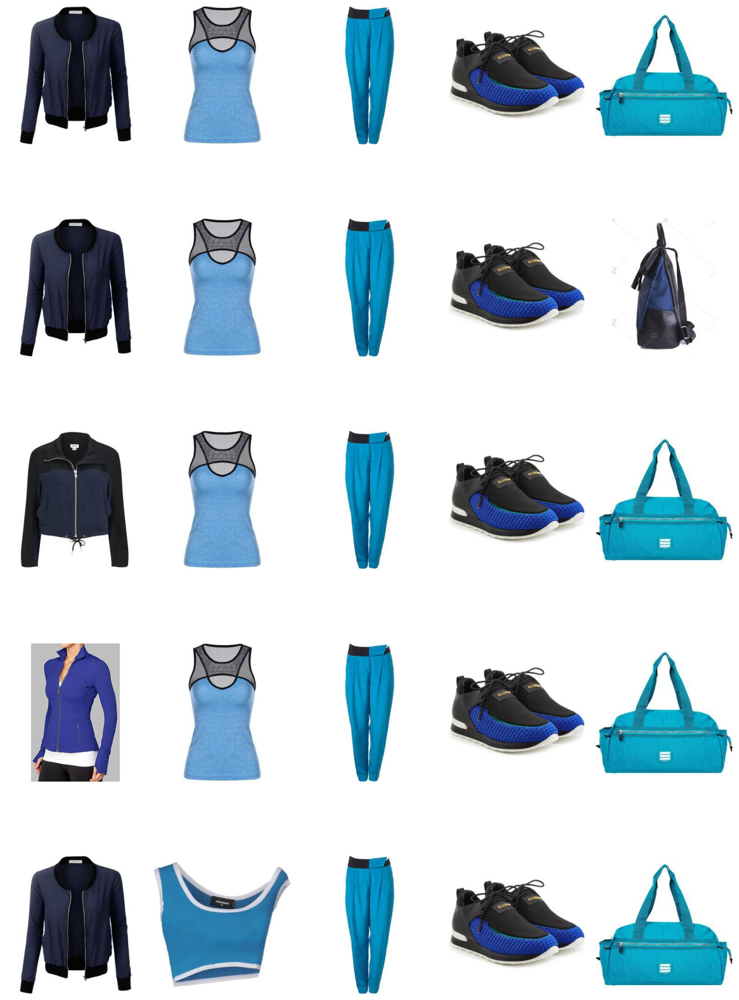

In [201]:
fig, axes = plt.subplots(
    5,
    5,
    figsize=(12, 18)
)

for row, outfit in enumerate(recommendations):

    for col, item_id in enumerate(outfit["item_ids"]):

        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"#{row + 1}\n"
        f"Score: {outfit['final_score']:.3f}\n"
        f"Compat: {outfit['compatibility_score']:.3f}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [203]:
def fashion_stylist(
    user_request,
    candidates_per_category=3,
    top_k=5
):

    # 1. LLM extracts preferences
    llm_response = extract_preferences_with_llm(
        user_request
    )

    # 2. Convert JSON string → Python dictionary
    preferences = parse_llm_preferences(
        llm_response
    )

    # 3. Build FashionCLIP queries
    queries = build_category_queries_from_preferences(
        preferences
    )

    # 4. Retrieve and rank outfits
    recommendations = recommend_outfits(
        queries,
        candidates_per_category=candidates_per_category,
        top_k=top_k
    )

    return {
        "request": user_request,
        "preferences": preferences,
        "queries": queries,
        "recommendations": recommendations
    }

In [204]:
result = fashion_stylist(
    "I want an elegant black outfit for a dinner date. "
    "I prefer something comfortable and not too revealing."
)

print("USER REQUEST:")
print(result["request"])

print("\nLLM PREFERENCES:")
print(result["preferences"])

print("\nFASHIONCLIP QUERIES:")

for category, query in result["queries"].items():
    print(category, "→", query)

print("\nRECOMMENDATIONS:")

for i, outfit in enumerate(
    result["recommendations"],
    1
):
    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])

USER REQUEST:
I want an elegant black outfit for a dinner date. I prefer something comfortable and not too revealing.

LLM PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

FASHIONCLIP QUERIES:
outerwear → elegant dinner date jacket black comfortable, not too revealing
tops → elegant dinner date top black comfortable, not too revealing
bottoms → elegant dinner date pants black comfortable, not too revealing
shoes → elegant dinner date shoes black comfortable, not too revealing
bags → elegant dinner date bag black comfortable, not too revealing

RECOMMENDATIONS:
1. Final: 0.8716 | Compatibility: 0.9914
Items: ['71516317', '210378897', '206302833', '146324638', '101375863']
2. Final: 0.8621 | Compatibility: 0.9910
Items: ['167480670', '210378897', '206302833', '146324638', '101375863']
3. Final: 0.8499 | Compatibility: 0.9915
Items: ['71516317', '210378897', '139644850', '146324638', '101375863

In [205]:
def build_category_queries_from_preferences(preferences):

    style = preferences.get("style", "")
    colors = preferences.get("colors", [])
    occasion = preferences.get("occasion", "")
    clothing_preferences = preferences.get(
        "clothing_preferences",
        []
    )

    # Convert lists to text
    color_text = ", ".join(colors)
    preference_text = ", ".join(clothing_preferences)

    # Defaults
    style_text = style if style else "fashionable"
    color_text = color_text if color_text else "any color"
    occasion_text = occasion if occasion else ""

    # Preferences relevant to clothing
    clothing_text = preference_text

    # Build category-specific queries
    queries = {

        "outerwear": (
            f"{style_text} {occasion_text} jacket "
            f"{color_text} {clothing_text}"
        ),

        "tops": (
            f"{style_text} {occasion_text} top "
            f"{color_text} {clothing_text}"
        ),

        "bottoms": (
            f"{style_text} {occasion_text} pants "
            f"{color_text} {clothing_text}"
        ),

        "shoes": (
            f"{style_text} {occasion_text} shoes "
            f"{color_text}"
        ),

        "bags": (
            f"{style_text} {occasion_text} bag "
            f"{color_text}"
        )
    }

    # Remove duplicate spaces and trailing commas
    queries = {
        category: " ".join(query.replace(",", " ").split())
        for category, query in queries.items()
    }

    return queries

In [206]:
queries = build_category_queries_from_preferences(
    result["preferences"]
)

for category, query in queries.items():
    print(category, "→", query)

outerwear → elegant dinner date jacket black comfortable not too revealing
tops → elegant dinner date top black comfortable not too revealing
bottoms → elegant dinner date pants black comfortable not too revealing
shoes → elegant dinner date shoes black
bags → elegant dinner date bag black


In [207]:
result = fashion_stylist(
    "I want an elegant black outfit for a dinner date. "
    "I prefer something comfortable and not too revealing."
)

print("LLM PREFERENCES:")
print(result["preferences"])

print("\nQUERIES:")

for category, query in result["queries"].items():
    print(category, "→", query)

print("\nRECOMMENDATIONS:")

for i, outfit in enumerate(
    result["recommendations"],
    1
):
    print(
        f"{i}. "
        f"Final: {outfit['final_score']:.4f} | "
        f"Compatibility: {outfit['compatibility_score']:.4f}"
    )

    print("Items:", outfit["item_ids"])

LLM PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

QUERIES:
outerwear → elegant dinner date jacket black comfortable not too revealing
tops → elegant dinner date top black comfortable not too revealing
bottoms → elegant dinner date pants black comfortable not too revealing
shoes → elegant dinner date shoes black
bags → elegant dinner date bag black

RECOMMENDATIONS:
1. Final: 0.9371 | Compatibility: 0.9905
Items: ['167480670', '210378897', '206302833', '183692897', '101375863']
2. Final: 0.9141 | Compatibility: 0.9908
Items: ['167480670', '210378897', '139644850', '183692897', '101375863']
3. Final: 0.8971 | Compatibility: 0.9899
Items: ['167480670', '210378897', '161848314', '183692897', '101375863']
4. Final: 0.8894 | Compatibility: 0.9895
Items: ['52036628', '210378897', '206302833', '183692897', '101375863']
5. Final: 0.8790 | Compatibility: 0.9901
Items: ['52036628', '210378897', '139

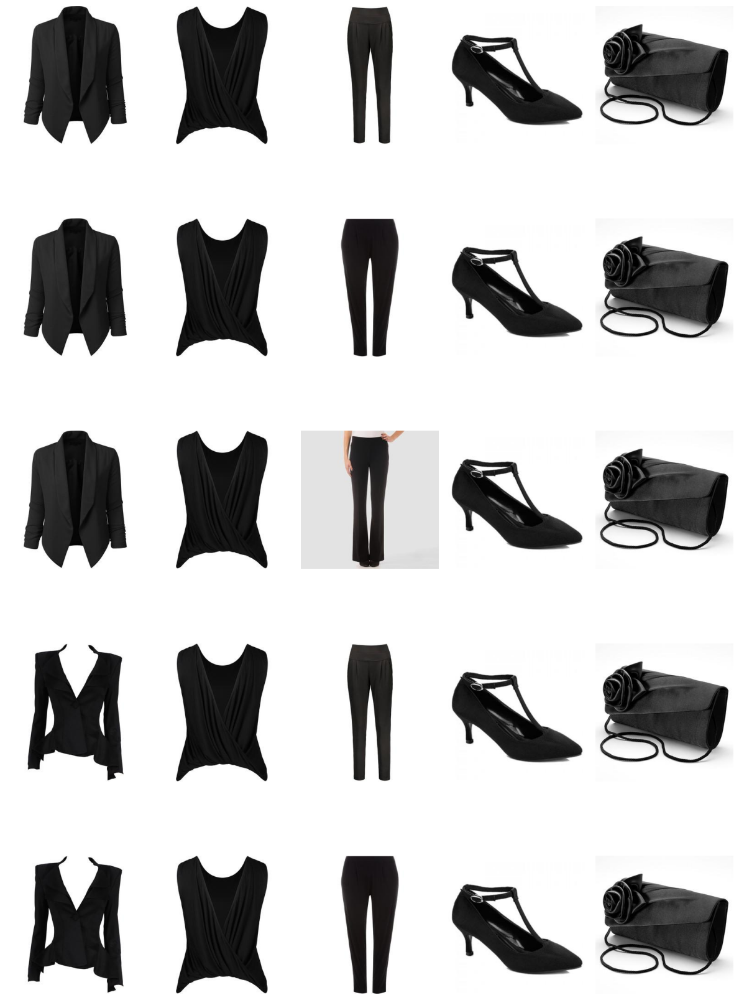

In [208]:
fig, axes = plt.subplots(
    5,
    5,
    figsize=(12, 18)
)

for row, outfit in enumerate(result["recommendations"]):

    for col, item_id in enumerate(outfit["item_ids"]):

        image_path = os.path.join(
            IMAGE_DIR,
            f"{item_id}.jpg"
        )

        image = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"#{row + 1}\n"
        f"Score: {outfit['final_score']:.3f}\n"
        f"Compat: {outfit['compatibility_score']:.3f}",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [209]:
def get_outfit_details(outfit):

    details = []

    for item_id in outfit["item_ids"]:

        item_id = str(item_id)

        row = metadata_df.loc[item_id]

        details.append({
            "item_id": item_id,
            "category": row["semantic_category"],
            "title": row["title"],
            "description": row["description"],
            "image_path": os.path.join(
                IMAGE_DIR,
                f"{item_id}.jpg"
            )
        })

    return {
        "items": details,
        "retrieval_score": outfit["retrieval_score"],
        "compatibility_score": outfit["compatibility_score"],
        "final_score": outfit["final_score"]
    }

In [210]:
top_outfit = get_outfit_details(
    result["recommendations"][0]
)

for item in top_outfit["items"]:

    print(
        item["category"],
        "→",
        item["item_id"]
    )

    print(
        "Image:",
        item["image_path"]
    )

    print()

outerwear → 167480670
Image: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/167480670.jpg

tops → 210378897
Image: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/210378897.jpg

bottoms → 206302833
Image: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/206302833.jpg

shoes → 183692897
Image: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/183692897.jpg

bags → 101375863
Image: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/images/101375863.jpg



In [211]:
def create_outfit_explanation_prompt(
    user_request,
    preferences,
    outfit_details
):

    item_descriptions = []

    for item in outfit_details["items"]:

        item_descriptions.append(
            f"""
Category: {item["category"]}
Item ID: {item["item_id"]}
Title: {item["title"]}
Description: {item["description"]}
"""
        )

    items_text = "\n".join(item_descriptions)

    prompt = f"""
You are a fashion recommendation assistant.

Explain why the following outfit is suitable for the user's request.

USER REQUEST:
{user_request}

USER PREFERENCES:
{preferences}

RETRIEVED OUTFIT:
{items_text}

RULES:
- Only mention information supported by the provided item information
  or the user's preferences.
- Do not invent materials, brands, colors, patterns, or clothing details.
- Explain how the pieces work together.
- Explain how the outfit matches the user's requested style and occasion.
- Keep the explanation concise and natural.

Write 2-4 sentences.
"""

    return prompt

In [212]:
explanation_prompt = create_outfit_explanation_prompt(
    user_request=result["request"],
    preferences=result["preferences"],
    outfit_details=top_outfit
)

print(explanation_prompt)


You are a fashion recommendation assistant.

Explain why the following outfit is suitable for the user's request.

USER REQUEST:
I want an elegant black outfit for a dinner date. I prefer something comfortable and not too revealing.

USER PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

RETRIEVED OUTFIT:

Category: outerwear
Item ID: 167480670
Title: 
Description: 


Category: tops
Item ID: 210378897
Title: Openback Cropped Sleeveless Tee
Description: Cheap Black Tees & T-Shirts online, Gamiss offers you Openback Cropped Sleeveless Tee, we also offer Wholesale service.


Category: bottoms
Item ID: 206302833
Title: Plus Size High Waisted Ankle Pants
Description: Plus Size High Waisted Ankle Pants


Category: shoes
Item ID: 183692897
Title: 
Description: 


Category: bags
Item ID: 101375863
Title: 
Description: 


RULES:
- Only mention information supported by the provided item information
  

In [213]:
def create_outfit_explanation_prompt(
    user_request,
    preferences,
    outfit_details
):

    item_descriptions = []

    for item in outfit_details["items"]:

        title = item["title"] if item["title"] else "Unknown"
        description = (
            item["description"]
            if item["description"]
            else "Unknown"
        )

        item_descriptions.append(
            f"""
Category: {item["category"]}
Item ID: {item["item_id"]}
Title: {title}
Description: {description}
"""
        )

    items_text = "\n".join(item_descriptions)

    prompt = f"""
You are a fashion recommendation assistant.

Analyze whether the retrieved outfit matches the user's request.

USER REQUEST:
{user_request}

USER PREFERENCES:
{preferences}

RETRIEVED OUTFIT:
{items_text}

RULES:
- Use ONLY information explicitly provided above.
- Never invent missing clothing details.
- If information about an item is missing, do not guess.
- Check whether the outfit actually satisfies the user's preferences.
- If an item conflicts with a stated preference, explicitly mention the conflict.
- Do not claim that an outfit is comfortable unless this is supported by the information.
- Do not claim that an outfit is modest or not revealing unless this is supported by the information.
- Explain which known items support the requested style or occasion.
- Be honest about uncertainty.
- Keep the explanation concise and natural.

Write 2-4 sentences.
"""

    return prompt

In [214]:
explanation_prompt = create_outfit_explanation_prompt(
    user_request=result["request"],
    preferences=result["preferences"],
    outfit_details=top_outfit
)

print(explanation_prompt)


You are a fashion recommendation assistant.

Analyze whether the retrieved outfit matches the user's request.

USER REQUEST:
I want an elegant black outfit for a dinner date. I prefer something comfortable and not too revealing.

USER PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

RETRIEVED OUTFIT:

Category: outerwear
Item ID: 167480670
Title: Unknown
Description: Unknown


Category: tops
Item ID: 210378897
Title: Openback Cropped Sleeveless Tee
Description: Cheap Black Tees & T-Shirts online, Gamiss offers you Openback Cropped Sleeveless Tee, we also offer Wholesale service.


Category: bottoms
Item ID: 206302833
Title: Plus Size High Waisted Ankle Pants
Description: Plus Size High Waisted Ankle Pants


Category: shoes
Item ID: 183692897
Title: Unknown
Description: Unknown


Category: bags
Item ID: 101375863
Title: Unknown
Description: Unknown


RULES:
- Use ONLY information explicitly 

In [215]:
messages = [
    {
        "role": "user",
        "content": explanation_prompt
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(llm.device)

with torch.no_grad():
    outputs = llm.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

explanation = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
)

print(explanation)

The retrieved outfit does not match the user's request for an elegant black outfit suitable for a dinner date. The top chosen (Openback Cropped Sleeveless Tee) is not black and lacks elegance. Additionally, the pants (Plus Size High Waisted Ankle Pants) are not black either. While the bag (Unknown) could potentially be used to carry the outfit, it doesn't align with the user's desire for comfort and modesty. Therefore, none of the available items satisfy both the color and style requirements while being comfortable and modest.


In [216]:
def create_outfit_explanation_prompt(
    user_request,
    preferences,
    outfit_details
):

    item_descriptions = []

    for item in outfit_details["items"]:

        title = item["title"] if item["title"] else "Unknown"
        description = (
            item["description"]
            if item["description"]
            else "Unknown"
        )

        item_descriptions.append(
            f"""
Category: {item["category"]}
Item ID: {item["item_id"]}
Title: {title}
Description: {description}
"""
        )

    items_text = "\n".join(item_descriptions)

    prompt = f"""
You are a fashion recommendation assistant.

Analyze whether the retrieved outfit matches the user's request.

USER REQUEST:
{user_request}

USER PREFERENCES:
{preferences}

RETRIEVED OUTFIT:
{items_text}

RULES:
- Use ONLY information explicitly provided above.
- Missing information means UNKNOWN, not NO.
- Do not infer a color when it is not explicitly stated.
- If the description explicitly says an item is black, treat it as black.
- Do not say an item is not black unless another color is explicitly provided.
- Do not invent comfort, modesty, fit, material, brand, or style.
- If an item is described as open-back, you may mention that this could conflict
  with the user's preference for something not too revealing.
- If you cannot determine whether a preference is satisfied, say so.
- Be honest about uncertainty.
- Keep the explanation concise and natural.

Write 2-4 sentences.
"""

    return prompt

In [217]:
explanation_prompt = create_outfit_explanation_prompt(
    result["request"],
    result["preferences"],
    top_outfit
)

messages = [
    {
        "role": "user",
        "content": explanation_prompt
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(llm.device)

with torch.no_grad():
    outputs = llm.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

explanation = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
)

print(explanation)

The retrieved outfit does not match the user's request for an elegant black outfit suitable for a dinner date. The top chosen is an Openback Cropped Sleeveless Tee, which is not black and could be considered not too revealing based on its design. The bottom is a Plus Size High Waisted Ankle Pants, which is not black either. There is no shoe or bag mentioned in the retrieval, nor any indication of comfort or material. Therefore, while there might be some elements that could potentially align with the user's preferences (like being black), they do not fully meet all the specified criteria.


In [218]:
for item in top_outfit["items"]:
    item_id = str(item["item_id"])
    row = metadata_df.loc[item_id]

    print("=" * 60)
    print("ITEM:", item_id)
    print("CATEGORY:", row["semantic_category"])
    print("TITLE:", repr(row["title"]))
    print("DESCRIPTION:", repr(row["description"]))

ITEM: 167480670
CATEGORY: outerwear
TITLE: ''
DESCRIPTION: ''
ITEM: 210378897
CATEGORY: tops
TITLE: 'Openback Cropped Sleeveless Tee'
DESCRIPTION: 'Cheap Black Tees & T-Shirts online, Gamiss offers you Openback Cropped Sleeveless Tee, we also offer Wholesale service.'
ITEM: 206302833
CATEGORY: bottoms
TITLE: 'Plus Size High Waisted Ankle Pants'
DESCRIPTION: 'Plus Size High Waisted Ankle Pants'
ITEM: 183692897
CATEGORY: shoes
TITLE: ''
DESCRIPTION: ''
ITEM: 101375863
CATEGORY: bags
TITLE: ''
DESCRIPTION: ''


In [219]:
def get_verified_item_attributes(item):

    item_id = str(item["item_id"])

    row = metadata_df.loc[item_id]

    title = row["title"] or ""
    description = row["description"] or ""

    text = f"{title} {description}".lower()

    attributes = []

    # Colors explicitly mentioned
    colors = [
        "black", "white", "red", "blue", "green",
        "pink", "beige", "brown", "gray", "grey",
        "cream", "navy"
    ]

    for color in colors:
        if color in text:
            attributes.append(color)

    # Explicit clothing characteristics
    characteristics = [
        "openback",
        "open-back",
        "cropped",
        "sleeveless",
        "high waisted",
        "high-waisted",
        "ankle pants",
        "oversized",
        "fitted",
        "long sleeve",
        "short sleeve"
    ]

    for characteristic in characteristics:
        if characteristic in text:
            attributes.append(characteristic)

    return {
        "item_id": item_id,
        "category": row["semantic_category"],
        "verified_attributes": attributes
    }

In [220]:
verified_items = []

for item in top_outfit["items"]:
    verified_items.append(
        get_verified_item_attributes(item)
    )

for item in verified_items:
    print(item)

{'item_id': '167480670', 'category': 'outerwear', 'verified_attributes': []}
{'item_id': '210378897', 'category': 'tops', 'verified_attributes': ['black', 'openback', 'cropped', 'sleeveless']}
{'item_id': '206302833', 'category': 'bottoms', 'verified_attributes': ['high waisted', 'ankle pants']}
{'item_id': '183692897', 'category': 'shoes', 'verified_attributes': []}
{'item_id': '101375863', 'category': 'bags', 'verified_attributes': []}


In [221]:
def create_grounded_explanation_prompt(
    user_request,
    preferences,
    verified_items
):

    item_text = []

    for item in verified_items:

        attributes = item["verified_attributes"]

        if attributes:
            attributes_text = ", ".join(attributes)
        else:
            attributes_text = "No verified attributes available"

        item_text.append(
            f"""
Category: {item["category"]}
Item ID: {item["item_id"]}
Verified attributes: {attributes_text}
"""
        )

    items_text = "\n".join(item_text)

    prompt = f"""
You are a fashion recommendation assistant.

Explain how well this retrieved outfit matches the user's request.

USER REQUEST:
{user_request}

USER PREFERENCES:
{preferences}

VERIFIED OUTFIT INFORMATION:
{items_text}

RULES:
- Use ONLY the verified attributes provided above.
- Never invent missing information.
- "No verified attributes available" means UNKNOWN.
- Do not infer colors, materials, comfort, fit, modesty, or style.
- If a verified attribute conflicts with a user preference, mention it.
- If there is not enough information to determine whether a preference
  is satisfied, say that it cannot be determined.
- Do not claim the outfit is perfect.
- Give an honest assessment.
- Keep the explanation natural and concise.

Write 2-4 sentences.
"""

    return prompt

In [222]:
grounded_prompt = create_grounded_explanation_prompt(
    user_request=result["request"],
    preferences=result["preferences"],
    verified_items=verified_items
)

print(grounded_prompt)


You are a fashion recommendation assistant.

Explain how well this retrieved outfit matches the user's request.

USER REQUEST:
I want an elegant black outfit for a dinner date. I prefer something comfortable and not too revealing.

USER PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

VERIFIED OUTFIT INFORMATION:

Category: outerwear
Item ID: 167480670
Verified attributes: No verified attributes available


Category: tops
Item ID: 210378897
Verified attributes: black, openback, cropped, sleeveless


Category: bottoms
Item ID: 206302833
Verified attributes: high waisted, ankle pants


Category: shoes
Item ID: 183692897
Verified attributes: No verified attributes available


Category: bags
Item ID: 101375863
Verified attributes: No verified attributes available


RULES:
- Use ONLY the verified attributes provided above.
- Never invent missing information.
- "No verified attributes available" 

In [223]:
messages = [
    {
        "role": "user",
        "content": grounded_prompt
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(llm.device)

with torch.no_grad():
    outputs = llm.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

grounded_explanation = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
).strip()

print(grounded_explanation)

The outfit you requested does not match your preferences as clearly as we would like. The top is black with an open back and cropped sleeves, which aligns with your color and style requests. However, the bottom is high-waisted ankle pants, which may make the outfit less comfortable than you'd prefer given your preference for being comfortable. Additionally, while the outfit is elegant in its design, it could potentially be more revealing due to the open back. Therefore, it can be concluded that the outfit partially meets your request but has some elements that do not fully satisfy all of your criteria.


In [224]:
def evaluate_outfit_preferences(preferences, verified_items):

    evaluation = {
        "color_match": "unknown",
        "comfort_match": "unknown",
        "modesty_match": "unknown",
        "style_match": "unknown",
        "occasion_match": "unknown"
    }

    all_attributes = []

    for item in verified_items:
        all_attributes.extend(item["verified_attributes"])

    # Color
    requested_colors = preferences.get("colors", [])

    if requested_colors:
        verified_colors = [
            color for color in requested_colors
            if color in all_attributes
        ]

        if verified_colors:
            evaluation["color_match"] = (
                f"Some items explicitly match the requested colors: "
                f"{', '.join(verified_colors)}"
            )

    # Comfort
    comfort_preferences = [
        "comfortable",
        "comfort"
    ]

    if any(
        preference in all_attributes
        for preference in comfort_preferences
    ):
        evaluation["comfort_match"] = "supported"

    # Modesty / revealing
    if "openback" in all_attributes or "open-back" in all_attributes:
        evaluation["modesty_match"] = (
            "potential_conflict: item is explicitly open-back"
        )

    # Style
    requested_style = preferences.get("style")

    if requested_style and requested_style in all_attributes:
        evaluation["style_match"] = "supported"

    # Occasion
    requested_occasion = preferences.get("occasion")

    if requested_occasion and requested_occasion in all_attributes:
        evaluation["occasion_match"] = "supported"

    return evaluation

In [225]:
outfit_evaluation = evaluate_outfit_preferences(
    result["preferences"],
    verified_items
)

print(outfit_evaluation)

{'color_match': 'Some items explicitly match the requested colors: black', 'comfort_match': 'unknown', 'modesty_match': 'potential_conflict: item is explicitly open-back', 'style_match': 'unknown', 'occasion_match': 'unknown'}


In [226]:
outfit_evaluation = {
    "color_match": {
        "status": "partial",
        "evidence": "The top is explicitly black. The colors of the other items are unknown."
    },
    "comfort_match": {
        "status": "unknown",
        "evidence": "No verified comfort information is available."
    },
    "modesty_match": {
        "status": "potential_conflict",
        "evidence": "The top is explicitly described as open-back."
    },
    "style_match": {
        "status": "unknown",
        "evidence": "No verified information confirms that the outfit is elegant."
    },
    "occasion_match": {
        "status": "unknown",
        "evidence": "No verified information confirms suitability for a dinner date."
    }
}

print(outfit_evaluation)

{'color_match': {'status': 'partial', 'evidence': 'The top is explicitly black. The colors of the other items are unknown.'}, 'comfort_match': {'status': 'unknown', 'evidence': 'No verified comfort information is available.'}, 'modesty_match': {'status': 'potential_conflict', 'evidence': 'The top is explicitly described as open-back.'}, 'style_match': {'status': 'unknown', 'evidence': 'No verified information confirms that the outfit is elegant.'}, 'occasion_match': {'status': 'unknown', 'evidence': 'No verified information confirms suitability for a dinner date.'}}


In [227]:
def create_final_explanation_prompt(
    user_request,
    preferences,
    verified_items,
    outfit_evaluation
):

    evaluation_text = "\n".join(
        [
            f"{key}: {value['status']} — {value['evidence']}"
            for key, value in outfit_evaluation.items()
        ]
    )

    item_text = "\n".join(
        [
            f"{item['category']}: "
            f"{', '.join(item['verified_attributes']) if item['verified_attributes'] else 'unknown'}"
            for item in verified_items
        ]
    )

    prompt = f"""
You are a fashion recommendation assistant.

Give a concise explanation of the retrieved outfit based on the
user's request and the system's verified evaluation.

USER REQUEST:
{user_request}

USER PREFERENCES:
{preferences}

VERIFIED ITEMS:
{item_text}

SYSTEM EVALUATION:
{evaluation_text}

IMPORTANT:
- Treat the SYSTEM EVALUATION as authoritative.
- Do not change its statuses.
- Do not invent missing information.
- Do not make new assumptions about comfort, elegance, modesty,
  colors, materials, or occasion suitability.
- Explain the strengths and limitations naturally.
- If something is unknown, say that it cannot be determined.
- If there is a potential conflict, mention it clearly.
- Do not pretend the outfit is better than the evidence supports.
- Keep the answer to 2-4 sentences.

Return only the explanation.
"""

    return prompt

In [228]:
final_prompt = create_final_explanation_prompt(
    user_request=result["request"],
    preferences=result["preferences"],
    verified_items=verified_items,
    outfit_evaluation=outfit_evaluation
)

print(final_prompt)


You are a fashion recommendation assistant.

Give a concise explanation of the retrieved outfit based on the
user's request and the system's verified evaluation.

USER REQUEST:
I want an elegant black outfit for a dinner date. I prefer something comfortable and not too revealing.

USER PREFERENCES:
{'style': 'elegant', 'colors': ['black'], 'occasion': 'dinner date', 'clothing_preferences': ['comfortable', 'not too revealing']}

VERIFIED ITEMS:
outerwear: unknown
tops: black, openback, cropped, sleeveless
bottoms: high waisted, ankle pants
shoes: unknown
bags: unknown

SYSTEM EVALUATION:
color_match: partial — The top is explicitly black. The colors of the other items are unknown.
comfort_match: unknown — No verified comfort information is available.
modesty_match: potential_conflict — The top is explicitly described as open-back.
style_match: unknown — No verified information confirms that the outfit is elegant.
occasion_match: unknown — No verified information confirms suitability fo

In [229]:
messages = [
    {
        "role": "user",
        "content": final_prompt
    }
]

text = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = tokenizer(
    text,
    return_tensors="pt"
).to(llm.device)

with torch.no_grad():
    outputs = llm.generate(
        **inputs,
        max_new_tokens=120,
        do_sample=False
    )

generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

final_explanation = tokenizer.decode(
    generated_tokens,
    skip_special_tokens=True
).strip()

print(final_explanation)

The user requested an elegant black outfit suitable for a dinner date, preferring comfort and modesty. However, the system evaluation indicates that while the top is black, the color of the outerwear, bottoms, shoes, and bags are unknown, making it difficult to confirm if the outfit meets all preferences. Additionally, the top being open-back may create a modesty issue, which could lead to a potential conflict with the user's preference. Therefore, the outfit does not fully match the user's expectations in terms of style, occasion, and modesty.


In [230]:
def generate_grounded_explanation(
    user_request,
    preferences,
    outfit_evaluation
):
    
    parts = []

    color = outfit_evaluation["color_match"]
    if color["status"] == "partial":
        parts.append(
            "The top is confirmed to be black, but the colors of "
            "the other items are unknown."
        )

    comfort = outfit_evaluation["comfort_match"]
    if comfort["status"] == "unknown":
        parts.append(
            "There is not enough verified information to determine "
            "whether the outfit is comfortable."
        )

    modesty = outfit_evaluation["modesty_match"]
    if modesty["status"] == "potential_conflict":
        parts.append(
            "The open-back top may conflict with the preference "
            "for something not too revealing."
        )

    style = outfit_evaluation["style_match"]
    if style["status"] == "unknown":
        parts.append(
            "There is not enough verified information to confirm "
            "that the outfit is elegant."
        )

    occasion = outfit_evaluation["occasion_match"]
    if occasion["status"] == "unknown":
        parts.append(
            "Its suitability for a dinner date cannot be confirmed "
            "from the available information."
        )

    return " ".join(parts)

In [231]:
final_explanation = generate_grounded_explanation(
    result["request"],
    result["preferences"],
    outfit_evaluation
)

print(final_explanation)

The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.


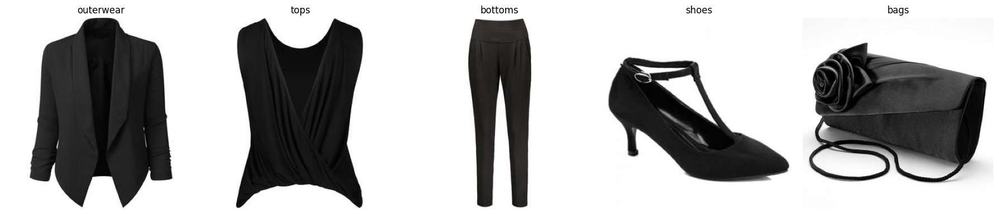

In [232]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    len(top_outfit["items"]),
    figsize=(18, 4)
)

for ax, item in zip(axes, top_outfit["items"]):

    image = Image.open(item["image_path"]).convert("RGB")

    ax.imshow(image)
    ax.set_title(
        item["category"],
        fontsize=12
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [233]:
def build_recommendation_result(
    result,
    outfit,
    verified_items,
    outfit_evaluation,
    explanation
):

    return {
        "request": result["request"],
        "preferences": result["preferences"],
        "outfit": {
            "items": outfit["items"],
            "retrieval_score": outfit["retrieval_score"],
            "compatibility_score": outfit["compatibility_score"],
            "final_score": outfit["final_score"]
        },
        "verified_items": verified_items,
        "evaluation": outfit_evaluation,
        "explanation": explanation
    }

In [234]:
recommendation = build_recommendation_result(
    result=result,
    outfit=top_outfit,
    verified_items=verified_items,
    outfit_evaluation=outfit_evaluation,
    explanation=final_explanation
)

print(recommendation["explanation"])

The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.


In [235]:
print("Final score:", recommendation["outfit"]["final_score"])
print("Compatibility score:", recommendation["outfit"]["compatibility_score"])
print("Retrieval score:", recommendation["outfit"]["retrieval_score"])

Final score: 0.9370584100074827
Compatibility score: 0.9905157089233398
Retrieval score: 0.3639319598674774


In [238]:
def evaluate_outfit_preferences(preferences, verified_items):

    evaluation = {
        "color_match": {
            "status": "unknown",
            "evidence": ""
        },
        "comfort_match": {
            "status": "unknown",
            "evidence": ""
        },
        "modesty_match": {
            "status": "unknown",
            "evidence": ""
        },
        "style_match": {
            "status": "unknown",
            "evidence": ""
        },
        "occasion_match": {
            "status": "unknown",
            "evidence": ""
        }
    }

    all_attributes = []

    for item in verified_items:
        all_attributes.extend(
            item["verified_attributes"]
        )

    # -------------------------
    # COLOR
    # -------------------------

    requested_colors = preferences.get("colors", [])

    if requested_colors:

        matched_colors = [
            color
            for color in requested_colors
            if color in all_attributes
        ]

        if matched_colors:
            evaluation["color_match"] = {
                "status": "partial",
                "evidence": (
                    f"The following requested colors are explicitly "
                    f"verified: {', '.join(matched_colors)}. "
                    "The colors of the other items are unknown."
                )
            }

    # -------------------------
    # COMFORT
    # -------------------------

    comfort_attributes = [
        "comfortable",
        "comfort"
    ]

    if any(
        attribute in all_attributes
        for attribute in comfort_attributes
    ):
        evaluation["comfort_match"] = {
            "status": "supported",
            "evidence": "Comfort is explicitly mentioned."
        }
    else:
        evaluation["comfort_match"] = {
            "status": "unknown",
            "evidence": (
                "No verified comfort information is available."
            )
        }

    # -------------------------
    # MODESTY
    # -------------------------

    if (
        "openback" in all_attributes
        or "open-back" in all_attributes
    ):
        evaluation["modesty_match"] = {
            "status": "potential_conflict",
            "evidence": (
                "The top is explicitly described as open-back."
            )
        }
    else:
        evaluation["modesty_match"] = {
            "status": "unknown",
            "evidence": (
                "There is not enough verified information "
                "to evaluate modesty."
            )
        }

    # -------------------------
    # STYLE
    # -------------------------

    requested_style = preferences.get("style")

    if (
        requested_style
        and requested_style in all_attributes
    ):
        evaluation["style_match"] = {
            "status": "supported",
            "evidence": (
                f"The style '{requested_style}' is explicitly verified."
            )
        }
    else:
        evaluation["style_match"] = {
            "status": "unknown",
            "evidence": (
                f"There is not enough verified information "
                f"to confirm that the outfit is {requested_style}."
            )
        }

    # -------------------------
    # OCCASION
    # -------------------------

    requested_occasion = preferences.get("occasion")

    if (
        requested_occasion
        and requested_occasion in all_attributes
    ):
        evaluation["occasion_match"] = {
            "status": "supported",
            "evidence": (
                f"The occasion '{requested_occasion}' is explicitly verified."
            )
        }
    else:
        evaluation["occasion_match"] = {
            "status": "unknown",
            "evidence": (
                "There is not enough verified information "
                "to confirm suitability for the requested occasion."
            )
        }

    return evaluation

In [239]:
top_3_outfits = []

for outfit in result["recommendations"][:3]:

    outfit_details = get_outfit_details(outfit)

    verified_items = []

    for item in outfit_details["items"]:
        verified_items.append(
            get_verified_item_attributes(item)
        )

    outfit_evaluation = evaluate_outfit_preferences(
        result["preferences"],
        verified_items
    )

    explanation = generate_grounded_explanation(
        result["request"],
        result["preferences"],
        outfit_evaluation
    )

    top_3_outfits.append({
        "outfit": outfit_details,
        "verified_items": verified_items,
        "evaluation": outfit_evaluation,
        "explanation": explanation
    })

print("Number of recommendations:", len(top_3_outfits))

for i, recommendation in enumerate(top_3_outfits, 1):

    print("\n" + "=" * 60)
    print("OUTFIT", i)

    print(
        "Final score:",
        recommendation["outfit"]["final_score"]
    )

    print(
        "Compatibility:",
        recommendation["outfit"]["compatibility_score"]
    )

    print(
        "Items:",
        [
            item["item_id"]
            for item in recommendation["outfit"]["items"]
        ]
    )

    print(
        "Explanation:",
        recommendation["explanation"]
    )

Number of recommendations: 3

OUTFIT 1
Final score: 0.9370584100074827
Compatibility: 0.9905157089233398
Items: ['167480670', '210378897', '206302833', '183692897', '101375863']
Explanation: The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.

OUTFIT 2
Final score: 0.9140836836906878
Compatibility: 0.9907642602920532
Items: ['167480670', '210378897', '139644850', '183692897', '101375863']
Explanation: The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for so

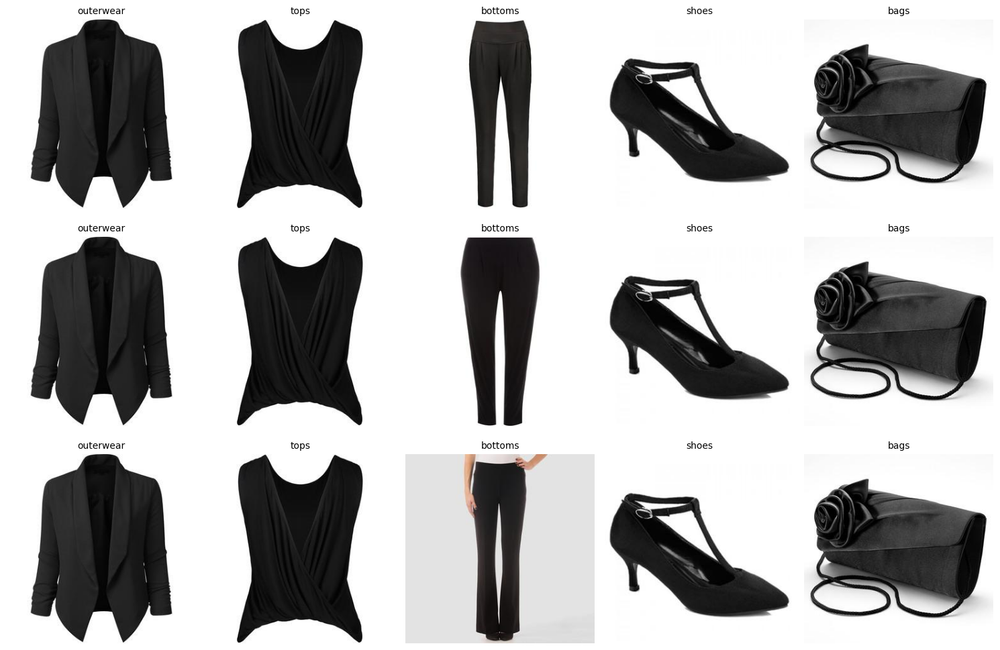

In [240]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 10)
)

categories = [
    "outerwear",
    "tops",
    "bottoms",
    "shoes",
    "bags"
]

for row, recommendation in enumerate(top_3_outfits):

    items = recommendation["outfit"]["items"]

    for col, item in enumerate(items):

        image = Image.open(
            item["image_path"]
        ).convert("RGB")

        axes[row, col].imshow(image)

        axes[row, col].set_title(
            categories[col],
            fontsize=10
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"Outfit {row + 1}",
        fontsize=14
    )

plt.tight_layout()
plt.show()

In [241]:
def display_outfit_recommendation(recommendation, outfit_number=1):

    items = recommendation["outfit"]["items"]

    fig, axes = plt.subplots(
        1,
        len(items),
        figsize=(18, 4)
    )

    for ax, item in zip(axes, items):

        image = Image.open(
            item["image_path"]
        ).convert("RGB")

        ax.imshow(image)

        ax.set_title(
            item["category"].capitalize(),
            fontsize=12
        )

        ax.axis("off")

    plt.suptitle(
        f"Outfit {outfit_number}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

    print(
        f"Final ranking score: "
        f"{recommendation['outfit']['final_score']:.4f}"
    )

    print(
        f"Compatibility score: "
        f"{recommendation['outfit']['compatibility_score']:.4f}"
    )

    print("\nExplanation:")
    print(recommendation["explanation"])

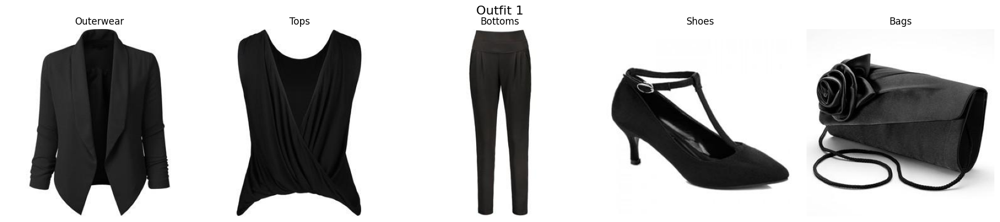

Final ranking score: 0.9371
Compatibility score: 0.9905

Explanation:
The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.


In [242]:
display_outfit_recommendation(
    top_3_outfits[0],
    outfit_number=1
)


RECOMMENDATION 1


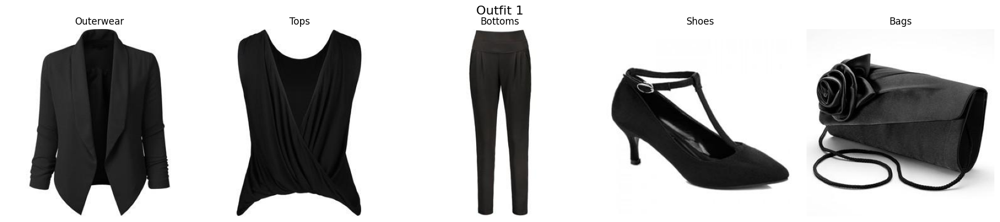

Final ranking score: 0.9371
Compatibility score: 0.9905

Explanation:
The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.

RECOMMENDATION 2


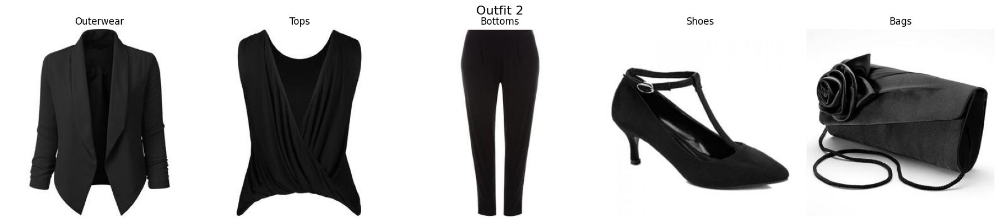

Final ranking score: 0.9141
Compatibility score: 0.9908

Explanation:
The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.

RECOMMENDATION 3


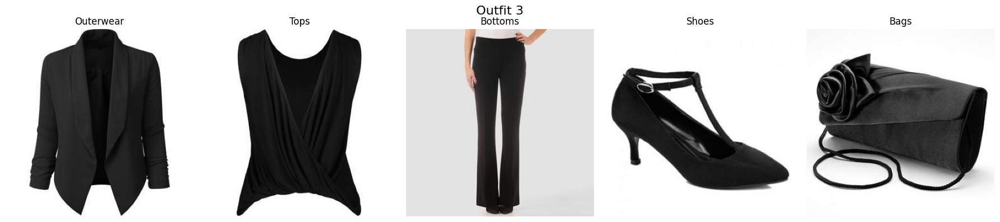

Final ranking score: 0.8971
Compatibility score: 0.9899

Explanation:
The top is confirmed to be black, but the colors of the other items are unknown. There is not enough verified information to determine whether the outfit is comfortable. The open-back top may conflict with the preference for something not too revealing. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.


In [243]:
for i, recommendation in enumerate(top_3_outfits, 1):

    print("\n" + "=" * 80)
    print(f"RECOMMENDATION {i}")
    print("=" * 80)

    display_outfit_recommendation(
        recommendation,
        outfit_number=i
    )

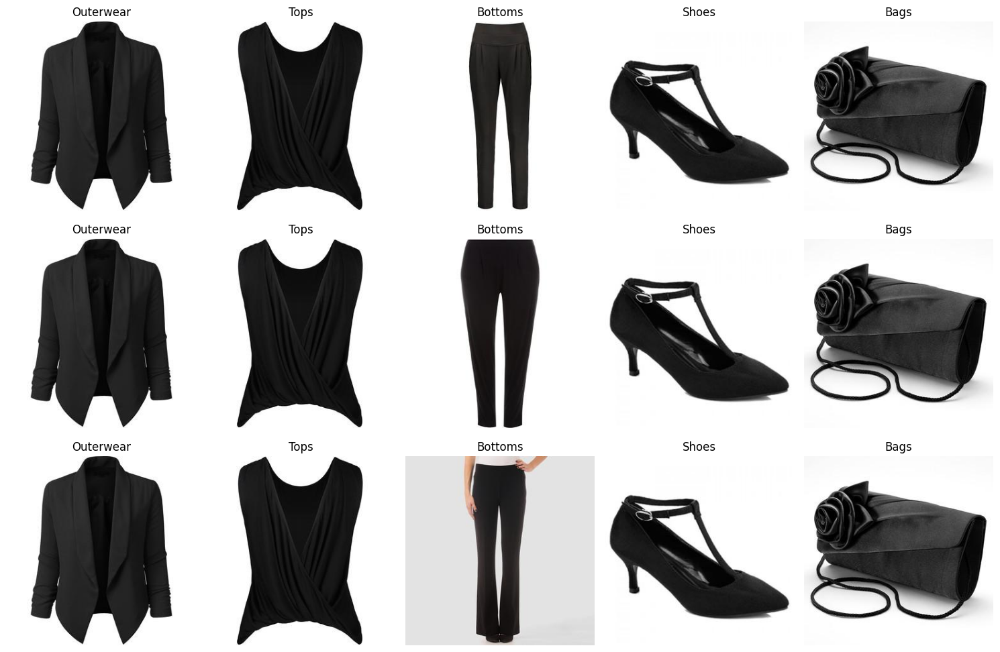

In [244]:
fig, axes = plt.subplots(
    3,
    5,
    figsize=(15, 10)
)

for row, recommendation in enumerate(top_3_outfits):

    items = recommendation["outfit"]["items"]

    for col, item in enumerate(items):

        image = Image.open(
            item["image_path"]
        ).convert("RGB")

        axes[row, col].imshow(image)

        axes[row, col].set_title(
            item["category"].capitalize()
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"Recommendation {row + 1}",
        fontsize=12
    )

plt.tight_layout()
plt.show()

In [245]:
def build_final_stylist_result(result, top_3_outfits):

    final_result = {
        "user_request": result["request"],
        "preferences": result["preferences"],
        "recommendations": []
    }

    for rank, recommendation in enumerate(top_3_outfits, 1):

        outfit = recommendation["outfit"]

        final_result["recommendations"].append({
            "rank": rank,
            "items": outfit["items"],
            "final_score": outfit["final_score"],
            "compatibility_score": outfit["compatibility_score"],
            "verified_items": recommendation["verified_items"],
            "evaluation": recommendation["evaluation"],
            "explanation": recommendation["explanation"]
        })

    return final_result

In [246]:
final_result = build_final_stylist_result(
    result,
    top_3_outfits
)

print(final_result.keys())

dict_keys(['user_request', 'preferences', 'recommendations'])


In [247]:
def run_fashion_stylist(
    user_request,
    candidates_per_category=3,
    top_k=3
):

    # 1. Extract preferences with the LLM
    llm_response = extract_preferences_with_llm(
        user_request
    )

    preferences = parse_llm_preferences(
        llm_response
    )

    # 2. Build category-specific retrieval queries
    queries = build_category_queries_from_preferences(
        preferences
    )

    # 3. Retrieve and rank outfits
    recommendations = recommend_outfits(
        queries,
        candidates_per_category=candidates_per_category,
        top_k=top_k
    )

    # 4. Evaluate each recommendation
    top_3_outfits = []

    for outfit in recommendations:

        outfit_details = get_outfit_details(
            outfit
        )

        verified_items = []

        for item in outfit_details["items"]:

            verified_items.append(
                get_verified_item_attributes(
                    item
                )
            )

        outfit_evaluation = evaluate_outfit_preferences(
            preferences,
            verified_items
        )

        explanation = generate_grounded_explanation(
            user_request,
            preferences,
            outfit_evaluation
        )

        top_3_outfits.append({
            "outfit": outfit_details,
            "verified_items": verified_items,
            "evaluation": outfit_evaluation,
            "explanation": explanation
        })

    # 5. Build final structured result
    final_result = build_final_stylist_result(
        {
            "request": user_request,
            "preferences": preferences
        },
        top_3_outfits
    )

    return final_result

In [248]:
new_request = """
I want a classy casual outfit for going shopping.
I prefer beige and white colors, comfortable clothes,
and nothing too tight.
"""

new_result = run_fashion_stylist(
    new_request
)

print(new_result["preferences"])
print(
    "Number of recommendations:",
    len(new_result["recommendations"])
)

{'style': 'casual', 'colors': ['beige', 'white'], 'occasion': 'shopping', 'clothing_preferences': ['comfortable']}
Number of recommendations: 3


In [249]:
from IPython.display import display, Markdown
from PIL import Image

def preview_fashion_stylist_result(result):

    print("USER REQUEST")
    print(result["user_request"])

    print("\nPREFERENCES")
    print(result["preferences"])

    for recommendation in result["recommendations"]:

        print("\n" + "=" * 70)
        print(f"RECOMMENDATION {recommendation['rank']}")
        print("=" * 70)

        print(
            f"Final score: "
            f"{recommendation['final_score']:.4f}"
        )

        print(
            f"Compatibility score: "
            f"{recommendation['compatibility_score']:.4f}"
        )

        print("\nItems:")

        for item in recommendation["items"]:

            print(
                f"- {item['category']}: "
                f"{item['item_id']}"
            )

        print("\nExplanation:")
        print(
            recommendation["explanation"]
        )

In [250]:
preview_fashion_stylist_result(
    new_result
)

USER REQUEST

I want a classy casual outfit for going shopping.
I prefer beige and white colors, comfortable clothes,
and nothing too tight.


PREFERENCES
{'style': 'casual', 'colors': ['beige', 'white'], 'occasion': 'shopping', 'clothing_preferences': ['comfortable']}

RECOMMENDATION 1
Final score: 0.9686
Compatibility score: 0.9585

Items:
- outerwear: 160101383
- tops: 76923338
- bottoms: 207548104
- shoes: 166330908
- bags: 170262970

Explanation:
There is not enough verified information to determine whether the outfit is comfortable. There is not enough verified information to confirm that the outfit is elegant. Its suitability for a dinner date cannot be confirmed from the available information.

RECOMMENDATION 2
Final score: 0.9563
Compatibility score: 0.9462

Items:
- outerwear: 160101383
- tops: 76931796
- bottoms: 207548104
- shoes: 166330908
- bags: 170262970

Explanation:
There is not enough verified information to determine whether the outfit is comfortable. There is not e

In [251]:
def generate_grounded_explanation(
    user_request,
    preferences,
    outfit_evaluation
):

    parts = []

    color = outfit_evaluation["color_match"]

    if color["status"] == "partial":
        parts.append(
            "Some requested colors are explicitly verified, "
            "but the colors of the other items are unknown."
        )

    comfort = outfit_evaluation["comfort_match"]

    if comfort["status"] == "unknown":
        parts.append(
            "There is not enough verified information to determine "
            "whether the outfit is comfortable."
        )

    modesty = outfit_evaluation["modesty_match"]

    if modesty["status"] == "potential_conflict":
        parts.append(
            "One item may conflict with your preference for "
            "less revealing clothing."
        )

    style = outfit_evaluation["style_match"]

    if style["status"] == "unknown":
        requested_style = preferences.get("style", "the requested style")

        parts.append(
            f"There is not enough verified information to confirm "
            f"that the outfit is {requested_style}."
        )

    occasion = outfit_evaluation["occasion_match"]

    if occasion["status"] == "unknown":
        requested_occasion = preferences.get(
            "occasion",
            "the requested occasion"
        )

        parts.append(
            f"I cannot verify the outfit's suitability for "
            f"{requested_occasion} from the available metadata."
        )

    if not parts:
        return (
            "The available verified information supports the "
            "main preferences for this outfit."
        )

    return " ".join(parts)

In [252]:
new_result = run_fashion_stylist(
    new_request
)

preview_fashion_stylist_result(
    new_result
)

USER REQUEST

I want a classy casual outfit for going shopping.
I prefer beige and white colors, comfortable clothes,
and nothing too tight.


PREFERENCES
{'style': 'casual', 'colors': ['beige', 'white'], 'occasion': 'shopping', 'clothing_preferences': ['comfortable']}

RECOMMENDATION 1
Final score: 0.9686
Compatibility score: 0.9585

Items:
- outerwear: 160101383
- tops: 76923338
- bottoms: 207548104
- shoes: 166330908
- bags: 170262970

Explanation:
There is not enough verified information to determine whether the outfit is comfortable. There is not enough verified information to confirm that the outfit is casual. I cannot verify the outfit's suitability for shopping from the available metadata.

RECOMMENDATION 2
Final score: 0.9563
Compatibility score: 0.9462

Items:
- outerwear: 160101383
- tops: 76931796
- bottoms: 207548104
- shoes: 166330908
- bags: 170262970

Explanation:
There is not enough verified information to determine whether the outfit is comfortable. There is not enoug

In [253]:
def extract_preferences_with_llm(user_request):

    prompt = f"""
You are a fashion preference extraction system.

Extract ONLY information explicitly stated by the user.

IMPORTANT RULES:
- Do NOT summarize or simplify the user's preferences.
- Preserve ALL style words.
- If multiple style words are given, keep all of them.
  Example: "classy casual" → "classy casual"
- Extract EVERY explicitly mentioned color.
- Extract the occasion.
- Extract EVERY clothing preference.
- Include preferences about fit, such as:
  tight, loose, oversized, fitted, relaxed, modest, revealing,
  not too tight, not revealing, comfortable, etc.
- Do not invent anything.
- Do not add synonyms that the user did not say.

Return ONLY valid JSON.

Required format:

{{
    "style": "",
    "colors": [],
    "occasion": "",
    "clothing_preferences": []
}}

User request:
"{user_request}"
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [257]:
test_request = """
I want a classy casual outfit for going shopping.
I prefer beige and white colors, comfortable clothes,
and nothing too tight.
"""

llm_response = extract_preferences_with_llm(
    test_request
)

print(llm_response)

```json
{
    "style": "casual",
    "colors": ["beige", "white"],
    "occasion": "shopping",
    "clothing_preferences": [
        "comfortable",
        "not too tight"
    ]
}
```


In [260]:
def parse_llm_preferences(response):

    response = response.strip()

    if response.startswith("```"):
        lines = response.splitlines()

        lines = lines[1:]

        if lines and lines[-1].strip() == "```":
            lines = lines[:-1]

        response = "\n".join(lines).strip()

    preferences = json.loads(response)

    return preferences

In [261]:
test_preferences = parse_llm_preferences(
    llm_response
)

print(test_preferences)

{'style': 'casual', 'colors': ['beige', 'white'], 'occasion': 'shopping', 'clothing_preferences': ['comfortable', 'not too tight']}


In [262]:
def extract_preferences_with_llm(user_request):

    prompt = f"""
You are a fashion preference extraction system.

Extract information ONLY from the user's exact words.

IMPORTANT:
- Preserve EVERY explicitly stated style.
- A user can request multiple styles.
- Put ALL style words into the "styles" list.
- Example:
  "classy casual outfit" →
  ["classy", "casual"]
- Extract EVERY explicitly mentioned color.
- Extract the occasion.
- Extract EVERY clothing preference.
- Preserve fit preferences such as:
  "not too tight", "loose", "oversized", "fitted", etc.
- Do NOT invent information.
- Do NOT remove explicitly stated preferences.
- Do NOT add synonyms.

Return ONLY valid JSON.

Required format:

{{
    "styles": [],
    "colors": [],
    "occasion": "",
    "clothing_preferences": []
}}

User request:
"{user_request}"
"""

    messages = [
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt"
    ).to(llm.device)

    with torch.no_grad():

        outputs = llm.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False
        )

    generated_tokens = outputs[0][
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    return response.strip()

In [263]:
llm_response = extract_preferences_with_llm(
    test_request
)

print(llm_response)

{
    "styles": ["classy", "casual"],
    "colors": ["beige", "white"],
    "occasion": "going shopping",
    "clothing_preferences": [
        "comfortable",
        "not too tight"
    ]
}


In [264]:
def build_category_queries_from_preferences(preferences):

    styles = preferences.get("styles", [])
    colors = preferences.get("colors", [])
    occasion = preferences.get("occasion", "")
    clothing_preferences = preferences.get(
        "clothing_preferences",
        []
    )

    style_text = " ".join(styles)
    color_text = " ".join(colors)
    preference_text = " ".join(clothing_preferences)

    queries = {

        "outerwear": (
            f"{style_text} {occasion} jacket "
            f"{color_text} {preference_text}"
        ),

        "tops": (
            f"{style_text} {occasion} top "
            f"{color_text} {preference_text}"
        ),

        "bottoms": (
            f"{style_text} {occasion} pants "
            f"{color_text} {preference_text}"
        ),

        "shoes": (
            f"{style_text} {occasion} shoes "
            f"{color_text}"
        ),

        "bags": (
            f"{style_text} {occasion} bag "
            f"{color_text}"
        )
    }

    queries = {
        category: " ".join(query.split())
        for category, query in queries.items()
    }

    return queries

In [265]:
test_queries = build_category_queries_from_preferences(
    test_preferences
)

for category, query in test_queries.items():
    print(f"{category}: {query}")

outerwear: shopping jacket beige white comfortable not too tight
tops: shopping top beige white comfortable not too tight
bottoms: shopping pants beige white comfortable not too tight
shoes: shopping shoes beige white
bags: shopping bag beige white


In [266]:
test_preferences = parse_llm_preferences(
    llm_response
)

print(test_preferences)

{'styles': ['classy', 'casual'], 'colors': ['beige', 'white'], 'occasion': 'going shopping', 'clothing_preferences': ['comfortable', 'not too tight']}


In [267]:
test_queries = build_category_queries_from_preferences(
    test_preferences
)

for category, query in test_queries.items():
    print(f"{category}: {query}")

outerwear: classy casual going shopping jacket beige white comfortable not too tight
tops: classy casual going shopping top beige white comfortable not too tight
bottoms: classy casual going shopping pants beige white comfortable not too tight
shoes: classy casual going shopping shoes beige white
bags: classy casual going shopping bag beige white


In [268]:
new_result = run_fashion_stylist(
    test_request
)

In [269]:
print("PREFERENCES:")
print(new_result["preferences"])

print("\nRECOMMENDATIONS:")

for recommendation in new_result["recommendations"]:

    print(
        f"\nRecommendation {recommendation['rank']}"
    )

    print(
        "Items:",
        [
            item["item_id"]
            for item in recommendation["items"]
        ]
    )

    print(
        "Final score:",
        round(
            recommendation["final_score"],
            4
        )
    )

PREFERENCES:
{'styles': ['classy', 'casual'], 'colors': ['beige', 'white'], 'occasion': 'going shopping', 'clothing_preferences': ['comfortable', 'not too tight']}

RECOMMENDATIONS:

Recommendation 1
Items: ['132676507', '76931796', '207548104', '29577851', '173070112']
Final score: 0.9047

Recommendation 2
Items: ['132676507', '76931796', '207548104', '29577851', '176171377']
Final score: 0.9047

Recommendation 3
Items: ['132676507', '76931796', '207548104', '60317041', '176171377']
Final score: 0.8956


In [270]:
for recommendation in new_result["recommendations"]:

    print("\n" + "=" * 70)
    print(
        f"RECOMMENDATION {recommendation['rank']}"
    )
    print("=" * 70)

    for item in recommendation["items"]:

        print(
            f"\n{item['category'].upper()}"
        )

        print(
            "ID:",
            item["item_id"]
        )

        print(
            "TITLE:",
            item["title"]
        )

        print(
            "DESCRIPTION:",
            item["description"]
        )


RECOMMENDATION 1

OUTERWEAR
ID: 132676507
TITLE: 
DESCRIPTION: 

TOPS
ID: 76931796
TITLE: Ruffled back blouse ivory
DESCRIPTION: Chest – 37 inches. Length – 22 inches. Polyester. Hand wash. Imported. For any style advice or inquiries, contact our stylist.

BOTTOMS
ID: 207548104
TITLE: 
DESCRIPTION: 

SHOES
ID: 29577851
TITLE: MAISON MARTIN MARGIELA 靴＆バッグのカタログ検索 | VOGUE.COM
DESCRIPTION: 

BAGS
ID: 173070112
TITLE: 
DESCRIPTION: 

RECOMMENDATION 2

OUTERWEAR
ID: 132676507
TITLE: 
DESCRIPTION: 

TOPS
ID: 76931796
TITLE: Ruffled back blouse ivory
DESCRIPTION: Chest – 37 inches. Length – 22 inches. Polyester. Hand wash. Imported. For any style advice or inquiries, contact our stylist.

BOTTOMS
ID: 207548104
TITLE: 
DESCRIPTION: 

SHOES
ID: 29577851
TITLE: MAISON MARTIN MARGIELA 靴＆バッグのカタログ検索 | VOGUE.COM
DESCRIPTION: 

BAGS
ID: 176171377
TITLE: 
DESCRIPTION: 

RECOMMENDATION 3

OUTERWEAR
ID: 132676507
TITLE: 
DESCRIPTION: 

TOPS
ID: 76931796
TITLE: Ruffled back blouse ivory
DESCRIPTION: Ches

In [271]:
def evaluate_outfit_preferences(preferences, verified_items):

    evaluation = {
        "color_match": {
            "status": "unknown",
            "evidence": ""
        },
        "comfort_match": {
            "status": "unknown",
            "evidence": ""
        },
        "fit_match": {
            "status": "unknown",
            "evidence": ""
        },
        "modesty_match": {
            "status": "unknown",
            "evidence": ""
        },
        "style_match": {
            "status": "unknown",
            "evidence": ""
        },
        "occasion_match": {
            "status": "unknown",
            "evidence": ""
        }
    }

    all_attributes = []

    for item in verified_items:
        all_attributes.extend(
            item["verified_attributes"]
        )

    # -------------------------
    # COLOR
    # -------------------------

    requested_colors = preferences.get(
        "colors",
        []
    )

    if requested_colors:

        matched_colors = [
            color
            for color in requested_colors
            if color in all_attributes
        ]

        if matched_colors:

            evaluation["color_match"] = {
                "status": "partial",
                "evidence": (
                    "The following requested colors are "
                    "explicitly verified: "
                    + ", ".join(matched_colors)
                )
            }

    # -------------------------
    # COMFORT
    # -------------------------

    if "comfortable" in all_attributes:

        evaluation["comfort_match"] = {
            "status": "supported",
            "evidence": (
                "Comfort is explicitly mentioned."
            )
        }

    # -------------------------
    # FIT
    # -------------------------

    clothing_preferences = [
        preference.lower()
        for preference in preferences.get(
            "clothing_preferences",
            []
        )
    ]

    fit_attributes = {
        "loose",
        "relaxed",
        "oversized",
        "fitted",
        "tight"
    }

    verified_fit = [
        attribute
        for attribute in all_attributes
        if attribute in fit_attributes
    ]

    if "not too tight" in clothing_preferences:

        if any(
            attribute in {
                "tight",
                "fitted"
            }
            for attribute in verified_fit
        ):

            evaluation["fit_match"] = {
                "status": "potential_conflict",
                "evidence": (
                    "An item is explicitly described "
                    "as fitted or tight."
                )
            }

        elif any(
            attribute in {
                "loose",
                "relaxed",
                "oversized"
            }
            for attribute in verified_fit
        ):

            evaluation["fit_match"] = {
                "status": "supported",
                "evidence": (
                    "An item is explicitly described "
                    "as loose, relaxed, or oversized."
                )
            }

        else:

            evaluation["fit_match"] = {
                "status": "unknown",
                "evidence": (
                    "There is not enough verified information "
                    "to determine the fit."
                )
            }

    # -------------------------
    # MODESTY
    # -------------------------

    if (
        "openback" in all_attributes
        or "open-back" in all_attributes
    ):

        evaluation["modesty_match"] = {
            "status": "potential_conflict",
            "evidence": (
                "An item is explicitly described "
                "as open-back."
            )
        }

    # -------------------------
    # STYLE
    # -------------------------

    styles = preferences.get(
        "styles",
        []
    )

    matched_styles = [
        style
        for style in styles
        if style in all_attributes
    ]

    if matched_styles:

        evaluation["style_match"] = {
            "status": "supported",
            "evidence": (
                "The following requested styles "
                "are explicitly verified: "
                + ", ".join(matched_styles)
            )
        }

    else:

        evaluation["style_match"] = {
            "status": "unknown",
            "evidence": (
                "There is not enough verified information "
                "to confirm the requested style."
            )
        }

    # -------------------------
    # OCCASION
    # -------------------------

    requested_occasion = preferences.get(
        "occasion",
        ""
    )

    if requested_occasion in all_attributes:

        evaluation["occasion_match"] = {
            "status": "supported",
            "evidence": (
                "The requested occasion is "
                "explicitly verified."
            )
        }

    else:

        evaluation["occasion_match"] = {
            "status": "unknown",
            "evidence": (
                "There is not enough verified information "
                "to confirm suitability for "
                + requested_occasion
                + "."
            )
        }

    return evaluation

In [272]:
def get_verified_item_attributes(item):

    item_id = str(item["item_id"])

    row = metadata_df.loc[item_id]

    title = row["title"] or ""
    description = row["description"] or ""

    text = f"{title} {description}".lower()

    attributes = []

    # Colors
    colors = [
        "black", "white", "red", "blue", "green",
        "pink", "beige", "brown", "gray", "grey",
        "cream", "navy"
    ]

    for color in colors:
        if color in text:
            attributes.append(color)

    # Clothing characteristics
    characteristics = [
        "openback",
        "open-back",
        "cropped",
        "sleeveless",
        "high waisted",
        "high-waisted",
        "ankle pants",
        "oversized",
        "fitted",
        "tight",
        "loose",
        "relaxed",
        "long sleeve",
        "short sleeve"
    ]

    for characteristic in characteristics:
        if characteristic in text:
            attributes.append(characteristic)

    return {
        "item_id": item_id,
        "category": row["semantic_category"],
        "verified_attributes": attributes
    }

In [273]:
for recommendation in new_result["recommendations"]:

    print(
        f"\nRECOMMENDATION {recommendation['rank']}"
    )

    for item in recommendation["items"]:

        verified = get_verified_item_attributes(item)

        print(
            item["category"],
            "→",
            verified["verified_attributes"]
        )


RECOMMENDATION 1
outerwear → []
tops → []
bottoms → []
shoes → []
bags → []

RECOMMENDATION 2
outerwear → []
tops → []
bottoms → []
shoes → []
bags → []

RECOMMENDATION 3
outerwear → []
tops → []
bottoms → []
shoes → []
bags → []


In [274]:
new_result = run_fashion_stylist(
    test_request
)

In [275]:
for recommendation in new_result["recommendations"]:

    print(
        f"\nRECOMMENDATION {recommendation['rank']}"
    )

    print(
        "Fit:",
        recommendation["evaluation"]["fit_match"]
    )

    print(
        "Explanation:",
        recommendation["explanation"]
    )


RECOMMENDATION 1
Fit: {'status': 'unknown', 'evidence': 'There is not enough verified information to determine the fit.'}
Explanation: There is not enough verified information to determine whether the outfit is comfortable. There is not enough verified information to confirm that the outfit is the requested style. I cannot verify the outfit's suitability for going shopping from the available metadata.

RECOMMENDATION 2
Fit: {'status': 'unknown', 'evidence': 'There is not enough verified information to determine the fit.'}
Explanation: There is not enough verified information to determine whether the outfit is comfortable. There is not enough verified information to confirm that the outfit is the requested style. I cannot verify the outfit's suitability for going shopping from the available metadata.

RECOMMENDATION 3
Fit: {'status': 'unknown', 'evidence': 'There is not enough verified information to determine the fit.'}
Explanation: There is not enough verified information to determin

In [277]:
import os

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if (
            file.endswith(".npy")
            or file.endswith(".pt")
            or file.endswith(".json")
        ):
            print(os.path.join(root, file))

/kaggle/working/outfit_compatibility_model.pt
/kaggle/working/fashion_embeddings/image_ids_full.npy
/kaggle/working/fashion_embeddings/image_embeddings_full.npy


In [278]:
import os

metadata_path = os.path.join(
    DATA_DIR,
    "polyvore_item_metadata.json"
)

print("Metadata path:", metadata_path)
print("Exists:", os.path.exists(metadata_path))

if os.path.exists(metadata_path):
    print("Size:", round(os.path.getsize(metadata_path) / (1024**2), 2), "MB")

Metadata path: /kaggle/input/datasets/yiitcandeime/polyvore/polyvore-outfit-dataset/polyvore_outfits/polyvore_item_metadata.json
Exists: True
Size: 73.29 MB


In [279]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 20.3 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 70.1 MB/s eta 0:00:00:00:010:01


In [280]:
import os
import shutil

EXPORT_DIR = "/kaggle/working/fashion_stylist_export"

os.makedirs(EXPORT_DIR, exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "models"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "embeddings"), exist_ok=True)
os.makedirs(os.path.join(EXPORT_DIR, "data"), exist_ok=True)

# Compatibility model
shutil.copy2(
    "/kaggle/working/outfit_compatibility_model.pt",
    os.path.join(EXPORT_DIR, "models", "outfit_compatibility_model.pt")
)

# Embeddings
shutil.copy2(
    "/kaggle/working/fashion_embeddings/image_embeddings_full.npy",
    os.path.join(EXPORT_DIR, "embeddings", "image_embeddings_full.npy")
)

shutil.copy2(
    "/kaggle/working/fashion_embeddings/image_ids_full.npy",
    os.path.join(EXPORT_DIR, "embeddings", "image_ids_full.npy")
)

# Metadata
shutil.copy2(
    os.path.join(DATA_DIR, "polyvore_item_metadata.json"),
    os.path.join(EXPORT_DIR, "data", "polyvore_item_metadata.json")
)

print("Export folder created:")
for root, dirs, files in os.walk(EXPORT_DIR):
    for file in files:
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"{path} — {size_mb:.1f} MB")

Export folder created:
/kaggle/working/fashion_stylist_export/data/polyvore_item_metadata.json — 73.3 MB
/kaggle/working/fashion_stylist_export/models/outfit_compatibility_model.pt — 20.0 MB
/kaggle/working/fashion_stylist_export/embeddings/image_ids_full.npy — 8.6 MB
/kaggle/working/fashion_stylist_export/embeddings/image_embeddings_full.npy — 490.3 MB
